---
## <font color=purple>  GRUPO DIAMOND FINDERS © </font>

---
INTEGRANTES:

* Gianella Silvestre Nina
* Andre de la Fuente
* Luis Atto Pintado

# <font color=purple>Hito 3: Revisión metodológica e implementación inicial</font>
## <font color=black>**Segmentación de proveedores en contrataciones de municipalidades provinciales del Perú según patrones de participación y adjudicación, 2021–2025**</font>

**Problema.** El OECE y las municipalidades provinciales no cuentan con una tipología de sus proveedores: se sabe cuántos hay, pero no cómo se diferencian en su forma de participar y de ganar contratos.

**Pregunta de análisis.** ¿Qué perfiles de proveedores se distinguen según su participación y adjudicación, y cómo se distribuyen en el territorio provincial?

**Alcance de los datos.** 47 281 proveedores que participaron entre el 4 de enero de 2021 y el 31 de diciembre de 2025 en las contrataciones de las **196 municipalidades provinciales**, incluida la **Municipalidad Metropolitana de Lima** (provincia de Lima)

**Segmentos identificados** (K-means, k = 6, sobre PCA de 3 componentes)

| N.° | Segmento | % de proveedores | Cómo se define |
|---:|---|---:|---|
| 0 | Ganadores de una sola vez | 29,5 % | Una convocatoria y la ganó |
| 1 | Postores de una sola vez sin éxito | 48,3 % | Una convocatoria y no ganó |
| 2 | Postores recurrentes sin éxito | 7,1 % | Varias convocatorias en varios meses y ninguna adjudicación |
| 3 | Ganadores recurrentes | 8,5 % | Varias convocatorias y adjudicaciones en al menos una |
| 4 | Generalistas multirrubro | 3,8 % | Operan en más de un rubro (2,05 en promedio) |
| 5 | Grandes operadores multimunicipales | 2,8 % | Mediana de 20 convocatorias, 8 municipalidades y más de 3 años de trayectoria |

**Contenido**

| N.° | Sección | Contenido |
|---:|---|---|
| 1 | Carga de datos y límites provinciales | Importación de la matriz integrada (con la provincia de Lima), de los límites provinciales y verificación de la cobertura. |
| 2 | Preparación de las variables | Selección de las 7 variables, transformación `log1p`, estandarización (Z-score) y correlaciones. |
| 3 | PCA | Número de componentes (regla del 85 % y Kaiser), cargas e interpretación de los componentes. |
| 4 | NMF | Elección de k por error de reconstrucción, lectura de los patrones y relación con PCA. |
| 5 | Matrices para clustering | Las tres representaciones que se comparan: 7 variables, PCA y NMF. |
| 6 | Métodos de clustering | 6.1 K-means, 6.2 DBSCAN, 6.3 Jerárquico (Ward) y 6.4 Comparación entre métodos, con métricas y ARI. |
| 7 | Selección provisional y estabilidad | Solución elegida (K-means, k = 6 sobre PCA), cruce con DBSCAN, estabilidad y definición de cada segmento. |
| 8 | Perfil de los segmentos | Nombres, tabla de perfil, mapa de calor, tamaño, concentración del monto, consorcio y penalidades. |
| 9 | Distribución territorial (provincias) | Mapa interactivo por provincia (GeoPandas y Plotly), el caso de Lima y composición por departamento. |
| 10 | Conclusiones preliminares | 10.1 decisiones y parámetros, 10.2 conclusiones y 10.3 qué cambió al incluir Lima. |
| 11 | Problemas y trabajo pendiente | Limitaciones identificadas y tareas antes del Hito 4. |
| 12 | Guardado de resultados | Exportación de etiquetas y tablas comparativas a CSV. |


# <font color=green>1. Carga de datos y límites provinciales</font>

In [ ]:
import json
import os
import subprocess
import unicodedata

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gpd
import plotly.graph_objects as go
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, NMF
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
sns.set_theme(style="ticks")

SEED = 1

In [ ]:
def normalizar_texto(texto):
    # mayúsculas y sin tildes, para cruzar nombres de distintas fuentes
    texto = unicodedata.normalize("NFKD", str(texto).upper().strip())
    return "".join(c for c in texto if not unicodedata.combining(c))


def metricas_particion(X, etiquetas):
    muestra = np.random.RandomState(SEED).choice(len(X), min(10000, len(X)), replace=False)
    return {
        "Silueta": silhouette_score(X[muestra], etiquetas[muestra]),
        "Davies_Bouldin": davies_bouldin_score(X, etiquetas),
        "Calinski_Harabasz": calinski_harabasz_score(X, etiquetas),
        "Tam_min": np.bincount(etiquetas).min(),
    }

In [ ]:
REPO_DATOS = "https://github.com/Protmdd/Matriz_Integrada_DM_OECE.git"
REPO_LIMITES = "https://github.com/josedaniel-cb/limites-peru-geojson.git"

for url, carpeta in [(REPO_DATOS, "Matriz_Integrada_DM_OECE"), (REPO_LIMITES, "limites-peru-geojson")]:
    if not os.path.exists(carpeta):
        subprocess.run(["git", "clone", "--depth", "1", url, carpeta], check=True)

df = pd.read_excel("Matriz_Integrada_DM_OECE/proveedores_integrado.xlsx", sheet_name="dataset_integrado")

# variables derivadas definidas en el Hito 2
df["n_municipalidades"] = df["municipalidades_participacion"].fillna("").apply(
    lambda t: len({m.strip() for m in str(t).split(",") if m.strip()}))
df["dias_trayectoria"] = (df["ultima_participacion"] - df["primera_participacion"]).dt.days

print("Proveedores (filas):", df.shape[0], "| columnas:", df.shape[1])
display(df[["ruc_proveedor", "n_convocatorias", "n_items_adjudicados", "tasa_adjudicacion",
            "monto_total_adjudicado", "n_municipalidades", "n_rubros", "dias_trayectoria"]].head())
provincias_datos = {p.strip() for t in df["provincias_participacion"].fillna("") for p in t.split(",") if p.strip()}
print("Provincias con participación:", len(provincias_datos))


Proveedores (filas): 47281 | columnas: 18


,ruc_proveedor,n_convocatorias,n_items_adjudicados,tasa_adjudicacion,monto_total_adjudicado,n_municipalidades,n_rubros,dias_trayectoria
0,10000196610,1,0,0.000,0.00,1,1,0
1,10000235071,3,1,0.333,96000.00,1,1,367
2,10000636369,2,1,0.500,55000.00,2,1,335
3,10000697945,12,3,0.214,506533.06,1,1,1096
4,10000701292,1,0,0.000,0.00,1,1,0


Provincias con participación: 196


**Cobertura de la matriz.** La matriz tiene **47 281 proveedores** y cubre las **196 provincias** del Perú, incluida la provincia de Lima (Municipalidad Metropolitana de Lima).


# <font color=green>2. Preparación de las variables</font>

**Unidad de análisis:** un proveedor. **Variables que entran a las técnicas (7):** `n_convocatorias`, `n_items_adjudicados`, `tasa_adjudicacion`, `monto_total_adjudicado`, `n_municipalidades`, `n_rubros`, `dias_trayectoria`.

**Variables que quedan fuera del modelo y por qué:**

| Variable | Motivo |
|---|---|
| `n_penalidades`, `monto_penalidades`, `tiene_penalidades` | Se usan después para perfilar los segmentos (Objetivo Específico 5). Si entraran al modelo, cruzar segmentos con penalidades sería circular |
| `participa_en_consorcio` | Es binaria y sirve para interpretar, no para medir distancias |
| Identificadores, nombres, fechas y listas de territorios | No son medidas numéricas del comportamiento (las fechas solo se usan para `dias_trayectoria`) |

**Transformación:** las variables de conteo, monto y días son muy asimétricas. Se aplica `log1p` a toda variable con asimetría mayor a 1; luego, Z-score para que ninguna variable domine por su escala.

In [ ]:
variables = ["n_convocatorias", "n_items_adjudicados", "tasa_adjudicacion", "monto_total_adjudicado",
             "n_municipalidades", "n_rubros", "dias_trayectoria"]

print("Nulos en las variables del modelo:", int(df[variables].isna().sum().sum()))

asimetria_antes = df[variables].skew()
cols_log = [c for c in variables if asimetria_antes[c] > 1]

X_log = df[variables].copy()
X_log[cols_log] = np.log1p(X_log[cols_log])

tabla_asimetria = pd.DataFrame({"Antes": asimetria_antes, "Despues": X_log.skew()})
tabla_asimetria["Transformada"] = tabla_asimetria.index.isin(cols_log)
display(tabla_asimetria.round(2))

Nulos en las variables del modelo: 0


,Antes,Despues,Transformada
n_convocatorias,49.83,2.90,True
n_items_adjudicados,102.96,1.80,True
tasa_adjudicacion,0.63,0.63,False
monto_total_adjudicado,28.20,0.35,True
n_municipalidades,13.85,3.82,True
n_rubros,5.30,5.05,True
dias_trayectoria,2.68,1.44,True


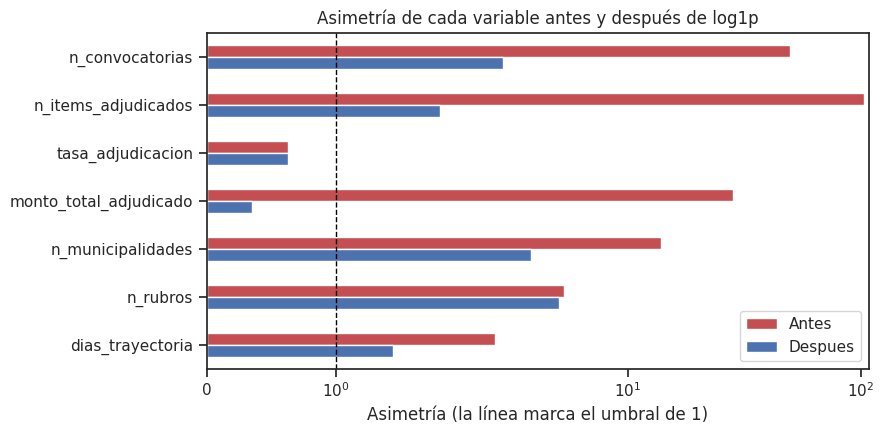

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
tabla_asimetria[["Antes", "Despues"]].plot.barh(ax=ax, color=["#c44e52", "#4c72b0"])
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set(title="Asimetría de cada variable antes y después de log1p", xlabel="Asimetría (la línea marca el umbral de 1)", xscale="symlog")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Qué muestra el gráfico.** Seis de las siete variables superan el umbral de asimetría de 1 y se transforman con `log1p`; solo `tasa_adjudicacion` (0,63) queda como está. La transformación reduce mucho la cola: `n_convocatorias` baja de 49,8 a 2,9, `n_items_adjudicados` de 103,0 a 1,8 y `monto_total_adjudicado` de 28,2 a 0,35.

**Excepción.** `n_rubros` casi no cambia (de 5,30 a 5,05): casi todos los proveedores tienen un solo rubro y unos pocos tienen varios, así que la cola no es continua. Se transforma igual para tratar todas las variables de conteo de la misma manera; los proveedores con varios rubros se capturan después con un componente propio (PCA) o un patrón propio (NMF).


In [ ]:
# prueba de la decisión: K-means con Z-score pero sin log1p
X_sin_log = StandardScaler().fit_transform(df[variables])

for k in [4, 5, 6]:
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_sin_log).labels_
    print(f"Sin log1p, k = {k}: tamaño de los clusters =", sorted(np.bincount(lab)))

Sin log1p, k = 4: tamaño de los clusters = [np.int64(1), np.int64(4428), np.int64(14872), np.int64(27980)]
Sin log1p, k = 5: tamaño de los clusters = [np.int64(1), np.int64(262), np.int64(4702), np.int64(15623), np.int64(26693)]
Sin log1p, k = 6: tamaño de los clusters = [np.int64(1), np.int64(204), np.int64(1788), np.int64(3921), np.int64(14672), np.int64(26695)]


**Por qué se usa `log1p`.** Sin la transformación, K-means separa **un solo proveedor** en un cluster propio con k = 4, 5 y 6, y casi todos los demás quedan repartidos en pocos clusters enormes (el mayor reúne entre 26 693 y 27 980 proveedores). En lugar de segmentar, el algoritmo aísla a un proveedor extremo. Con `log1p` el cluster más pequeño de k = 6 tiene 1 276 proveedores (sección 6).


In [ ]:
X_z = StandardScaler().fit_transform(X_log)

print("Media máxima en valor absoluto:", np.abs(X_z.mean(axis=0)).max().round(6))
print("Desviaciones estándar:", X_z.std(axis=0).round(2))

# muestra común para comparar siluetas de distintas representaciones
muestra_z = np.random.RandomState(SEED).choice(len(df), 10000, replace=False)

# justificación del escalador: un RobustScaler divide entre el rango intercuartil
iqr = X_log.quantile(0.75) - X_log.quantile(0.25)
display(iqr.round(3).to_frame("Rango_intercuartil"))

print("Proveedores con un perfil exactamente repetido:", f"{pd.DataFrame(X_z).round(6).duplicated().mean():.1%}")

Media máxima en valor absoluto: 0.0
Desviaciones estándar: [1. 1. 1. 1. 1. 1. 1.]


,Rango_intercuartil
n_convocatorias,0.405
n_items_adjudicados,0.693
tasa_adjudicacion,1.000
monto_total_adjudicado,12.117
n_municipalidades,0.000
n_rubros,0.000
dias_trayectoria,0.000


Proveedores con un perfil exactamente repetido: 53.9%


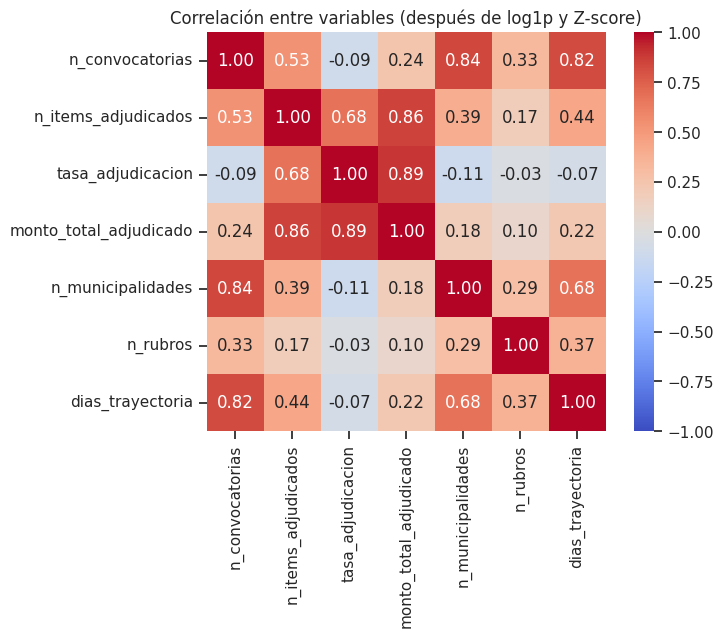

In [ ]:
correlaciones = pd.DataFrame(X_z, columns=variables).corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set(title="Correlación entre variables (después de log1p y Z-score)")
plt.tight_layout()
plt.show()

**Qué muestra el mapa de calor.** Las variables forman dos bloques que se parecen internamente:

- **Participación:** `n_convocatorias` con `n_municipalidades` (0,84) y con `dias_trayectoria` (0,82); `n_municipalidades` con `dias_trayectoria` (0,68). Quien participa más, llega a más municipalidades y durante más tiempo.
- **Resultado:** `tasa_adjudicacion` con `monto_total_adjudicado` (0,89), `n_items_adjudicados` con el monto (0,86) y con la tasa (0,68).

Los dos bloques casi no se relacionan entre sí (por ejemplo, `n_convocatorias` con `tasa_adjudicacion` vale -0,09): participar mucho no implica ganar más. `n_rubros` es la variable más independiente (correlación máxima de 0,37). Esta redundancia dentro de cada bloque es lo que justifica reducir dimensión con PCA.

**Por qué `StandardScaler` y no `RobustScaler`.** El rango intercuartil de `n_municipalidades`, `n_rubros` y `dias_trayectoria` es 0, porque más de la mitad de los proveedores comparte un mismo valor (una municipalidad, un rubro, cero días). Un `RobustScaler` dejaría esas tres variables sin escalar y, a la vez, dividiría el monto entre 12,1 y las convocatorias entre 0,4: cada variable tendría un peso arbitrario. El Z-score da a todas la misma escala (media 0 y desviación 1).

**Perfiles repetidos.** El 53,9 % de los proveedores tiene exactamente el mismo perfil que otro (por ejemplo, una convocatoria sin adjudicación). Esto obliga a tener cuidado con la silueta (se infla) y con DBSCAN (se resuelve con pesos, sección 6.2).


# <font color=green>3. PCA</font>

**Para qué:** las variables están correlacionadas (se ve en el mapa de calor anterior), así que varias miden casi lo mismo. PCA las reemplaza por pocos componentes que no se correlacionan entre sí y resume la información.

**Cuántos componentes se conservan.** Se comparan dos criterios estándar:

- **Regla del 85 %:** el menor número de componentes cuya varianza acumulada llega a 85 %.
- **Criterio de Kaiser:** componentes con autovalor mayor a 1 (con datos estandarizados, un componente que explica menos que una variable original).


In [ ]:
pca = PCA(random_state=SEED).fit(X_z)

tabla_pca = pd.DataFrame({
    "Componente": [f"Z{i + 1}" for i in range(len(variables))],
    "Autovalor": pca.explained_variance_,
    "Varianza_pct": 100 * pca.explained_variance_ratio_,
})
tabla_pca["Acumulada_pct"] = tabla_pca["Varianza_pct"].cumsum()
display(tabla_pca.round(2))

n_regla85 = int(np.argmax(tabla_pca["Acumulada_pct"].values >= 85) + 1)
n_kaiser = int((tabla_pca["Autovalor"] > 1).sum())
print("Componentes según la regla del 85 %:", n_regla85, "| según Kaiser:", n_kaiser)

,Componente,Autovalor,Varianza_pct,Acumulada_pct
0,Z1,3.37,48.15,48.15
1,Z2,2.20,31.37,79.52
2,Z3,0.83,11.86,91.38
3,Z4,0.32,4.51,95.90
4,Z5,0.17,2.48,98.38
5,Z6,0.07,0.97,99.35
6,Z7,0.05,0.65,100.00


Componentes según la regla del 85 %: 3 | según Kaiser: 2


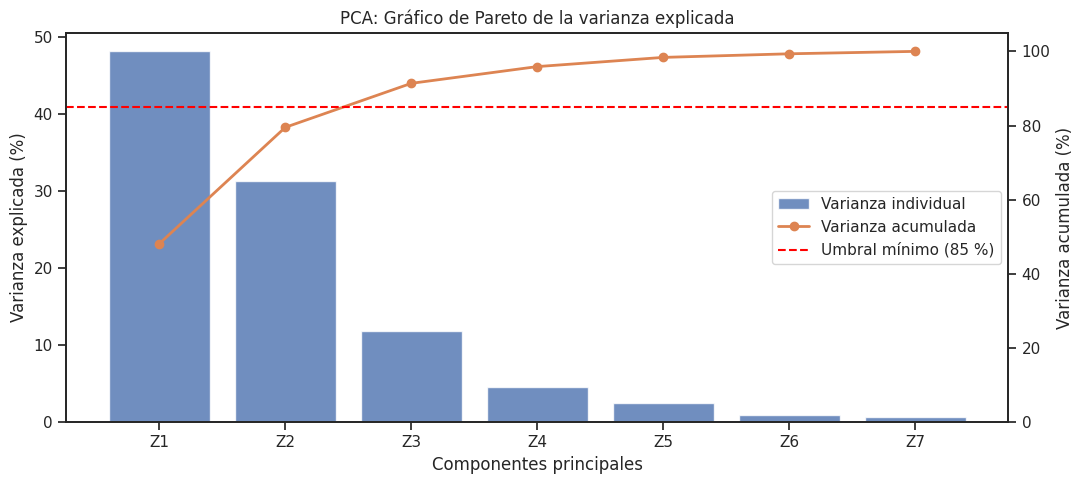

In [ ]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.bar(tabla_pca["Componente"], tabla_pca["Varianza_pct"],
        color="#4c72b0", alpha=0.8, label="Varianza individual")

ax1.set_xlabel("Componentes principales")
ax1.set_ylabel("Varianza explicada (%)")
ax1.set_xticks(tabla_pca["Componente"])

ax2 = ax1.twinx()
ax2.plot(tabla_pca["Componente"], tabla_pca["Acumulada_pct"],
         color="#dd8452", marker="o", linewidth=2, label="Varianza acumulada")

ax2.axhline(85, color="red", linestyle="--", label="Umbral mínimo (85 %)")
ax2.set_ylabel("Varianza acumulada (%)")
ax2.set_ylim(0, 105)

lineas1, etiquetas1 = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()
ax1.legend(lineas1 + lineas2, etiquetas1 + etiquetas2, loc="center right")

ax1.set_title("PCA: Gráfico de Pareto de la varianza explicada")
plt.tight_layout()
plt.show()


**Decisión: 3 componentes.** Los dos criterios no coinciden: la regla del 85 % pide 3 componentes (91,4 % de la varianza) y Kaiser pide 2. Se eligen 3 por tres razones:

1. Con 2 componentes la varianza acumulada es 79,52 %: queda 5,48 puntos por debajo del umbral.
2. El autovalor del tercer componente (0,83) está cerca de 1, no lejos.
3. Z3 es el único componente que representa `n_rubros` (carga de 0,95), una variable que los otros dos casi no recogen. Sin Z3 no se podría distinguir a los proveedores multirrubro, que en la sección 8 se separan con +5,0 desviaciones estándar en esa variable.


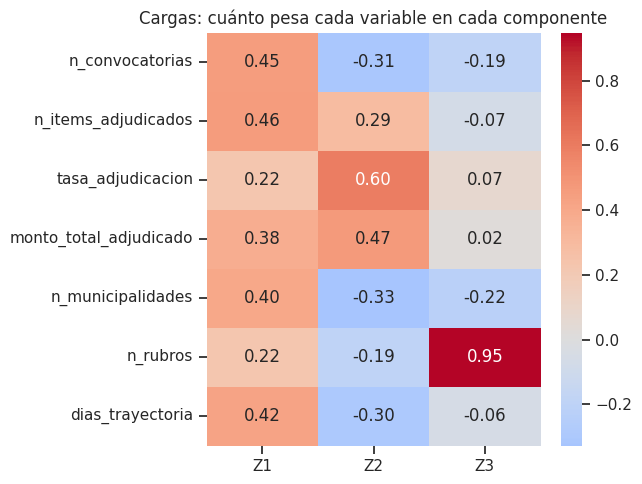

In [ ]:
n_pca = n_regla85
Z_pca = pca.transform(X_z)[:, :n_pca]

cargas = pd.DataFrame(pca.components_[:n_pca].T, index=variables, columns=[f"Z{i + 1}" for i in range(n_pca)])

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set(title="Cargas: cuánto pesa cada variable en cada componente")
plt.tight_layout()
plt.show()

**Cómo leer los componentes** (cada carga indica cuánto pesa la variable en el componente; el signo indica el sentido):

- **Z1 (48,1 % de la varianza): actividad global.** Todas las cargas son positivas (convocatorias 0,45, ítems 0,46, días 0,42, municipalidades 0,40, monto 0,38). Un proveedor con Z1 alto participa mucho, durante mucho tiempo y en muchas municipalidades.
- **Z2 (31,4 %): eficacia frente a extensión.** Pesan positivo la tasa de adjudicación (0,60), el monto (0,47) y los ítems (0,29), y negativo las convocatorias (-0,31), las municipalidades (-0,33) y los días (-0,30). Z2 alto significa ganar bastante con poca participación; Z2 bajo, participar mucho sin ganar.
- **Z3 (11,9 %): diversificación.** Solo `n_rubros` pesa (0,95): separa a quienes operan en varios rubros.



# <font color=green>4. NMF</font>

**Para qué:** NMF descompone cada proveedor como una suma de "patrones" que solo se pueden sumar (no hay pesos negativos). Eso lo hace más fácil de leer que PCA: cada patrón es un tipo de comportamiento y cada proveedor tiene un peso en cada patrón.


,k,Error_relativo_pct
0,2,20.25
1,3,15.73
2,4,9.80
3,5,5.40
4,6,3.01


k elegido para NMF: 4


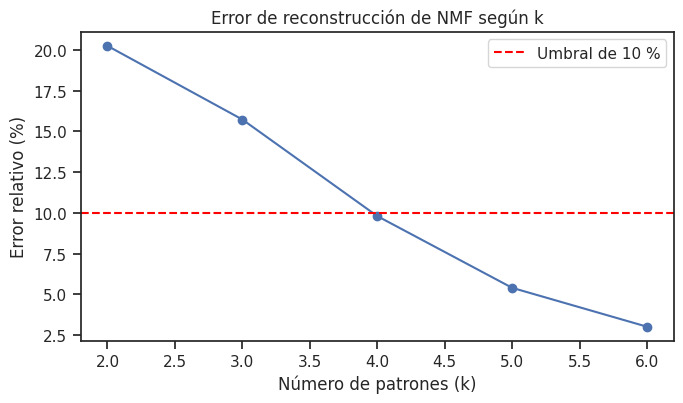

In [ ]:
X_nmf = MinMaxScaler().fit_transform(X_log)
norma = np.linalg.norm(X_nmf)

filas = []
for k in range(2, 7):
    modelo = NMF(n_components=k, init="nndsvda", random_state=SEED, max_iter=600).fit(X_nmf)
    filas.append({"k": k, "Error_relativo_pct": 100 * modelo.reconstruction_err_ / norma})
tabla_nmf = pd.DataFrame(filas)
display(tabla_nmf.round(2))

k_nmf = int(tabla_nmf.loc[tabla_nmf["Error_relativo_pct"] <= 10, "k"].min())
print("k elegido para NMF:", k_nmf)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(tabla_nmf["k"], tabla_nmf["Error_relativo_pct"], marker="o", color="#4c72b0")
ax.axhline(10, color="red", linestyle="--", label="Umbral de 10 %")
ax.set(title="Error de reconstrucción de NMF según k", xlabel="Número de patrones (k)", ylabel="Error relativo (%)")
ax.legend()
plt.tight_layout()
plt.show()

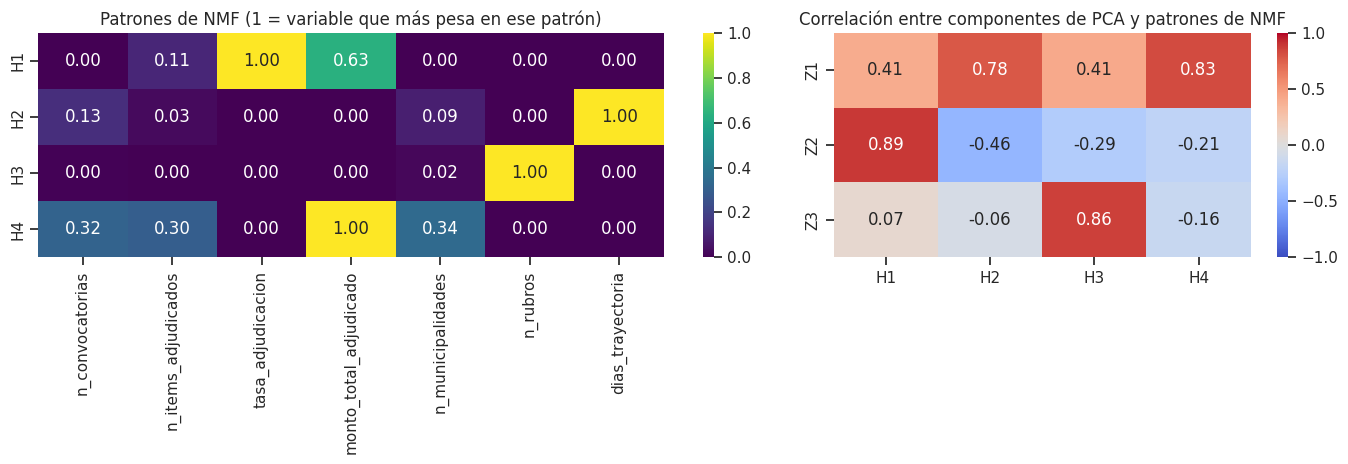

In [ ]:
nmf = NMF(n_components=k_nmf, init="nndsvda", random_state=SEED, max_iter=600).fit(X_nmf)
W_nmf = nmf.transform(X_nmf)

# cada patrón se divide entre su valor máximo para que sea comparable
patrones = pd.DataFrame(nmf.components_, index=[f"H{i + 1}" for i in range(k_nmf)], columns=variables)
patrones = patrones.div(patrones.max(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

sns.heatmap(patrones, annot=True, fmt=".2f", cmap="viridis", ax=axes[0])
axes[0].set(title="Patrones de NMF (1 = variable que más pesa en ese patrón)")

relacion = pd.DataFrame(
    np.corrcoef(Z_pca.T, W_nmf.T)[:n_pca, n_pca:],
    index=[f"Z{i + 1}" for i in range(n_pca)], columns=[f"H{i + 1}" for i in range(k_nmf)])
sns.heatmap(relacion, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set(title="Correlación entre componentes de PCA y patrones de NMF")

plt.tight_layout()
plt.show()

**Decisión: k = 4.** El error de reconstrucción baja de 20,2 % (k = 2) a 15,7 % (k = 3), 9,8 % (k = 4) y 5,4 % (k = 5). Con k = 4 se cruza por primera vez el umbral de 10 %. No hay un codo marcado (el error baja de forma gradual), por lo que el umbral fijado de antemano es lo que sustenta la elección.

**Cómo leer los patrones** (cada fila es un patrón; 1 indica la variable que más pesa en él):

- **H1: eficacia.** Domina la tasa de adjudicación (1,00) con el monto (0,63).
- **H2: trayectoria larga.** Domina `dias_trayectoria` (1,00).
- **H3: diversificación.** Solo pesa `n_rubros` (1,00).
- **H4: escala.** Domina el monto (1,00) junto con municipalidades, convocatorias e ítems (entre 0,30 y 0,34): grandes montos con alcance multi-municipal.

**Relación con PCA**: hay una correspondencia clara entre Z2 y H1 (0,89, eficacia) y entre Z3 y H3 (0,86, diversificación). El componente de actividad Z1 de PCA se reparte en dos patrones de NMF: H4 (0,83, escala) y H2 (0,78, trayectoria). Es decir, NMF descompone la actividad global en dos formas distintas de ser activo, lo que PCA mantiene unido.


# <font color=green>5. Matrices para clustering</font>

Se comparan tres representaciones de los mismos 47 281 proveedores. Todas parten de `log1p`.


In [ ]:
representaciones = {
    "Z (7 variables)": X_z,
    f"PCA ({n_pca} componentes)": Z_pca,
    f"NMF ({k_nmf} patrones)": W_nmf,
}

resumen = pd.DataFrame({
    "Filas": [X.shape[0] for X in representaciones.values()],
    "Columnas": [X.shape[1] for X in representaciones.values()],
    "Escalado": ["log1p + Z-score", "log1p + Z-score + PCA", "log1p + MinMax + NMF"],
}, index=representaciones.keys())
display(resumen)

,Filas,Columnas,Escalado
Z (7 variables),47281,7,log1p + Z-score
PCA (3 componentes),47281,3,log1p + Z-score + PCA
NMF (4 patrones),47281,4,log1p + MinMax + NMF


# <font color=green>6. Métodos de clustering</font>

**Por qué clustering.** No existe una variable que indique el tipo de proveedor, así que se usa un método no supervisado para encontrar grupos con comportamiento parecido.

| Método | Qué aporta | Limitación a vigilar |
|---|---|---|
| **K-means** | Segmentos descritos por un centroide fácil de interpretar; escala a 47 281 filas | Hay que fijar k; es sensible a valores extremos |
| **DBSCAN** | Encuentra zonas densas y marca ruido, sin fijar k | Los parámetros `eps` y `min_samples` cambian mucho el resultado |
| **Jerárquico (Ward)** | No depende de una inicialización aleatoria: sirve para confirmar si K-means encontró una estructura real | No cabe en memoria con 47 281 filas; se aplica a una muestra |

**Métricas** (se explican porque se reutilizan en todo el apartado):

- **Silueta** (de -1 a 1, más alta es mejor): qué tan cerca está cada proveedor de su grupo frente al grupo vecino.
- **Davies-Bouldin** (más bajo es mejor): cuánto se parecen entre sí los grupos.
- **Calinski-Harabasz** (más alto es mejor): separación entre grupos frente a dispersión dentro de cada uno.
- **Tamaño del cluster más pequeño** (%): descarta soluciones que solo aíslan unos pocos proveedores.
- **ARI entre semillas** (de 0 a 1): si al repetir con otra semilla se obtiene el mismo agrupamiento.

**6.1 K-means.** k de 2 a 8, `n_init = 10`, sobre las tres representaciones. Como las siluetas de espacios distintos no son comparables, se calcula también la silueta de cada partición en un espacio común (`Silueta_en_Z`, el de las 7 variables).


In [ ]:
def evaluar_kmeans(X, nombre, rango_k):
    filas = []
    for k in rango_k:
        modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        otras_semillas = [KMeans(n_clusters=k, n_init=10, random_state=s).fit(X).labels_ for s in (2, 3)]

        fila = {"Representacion": nombre, "k": k, "Inercia": modelo.inertia_}
        fila.update(metricas_particion(X, modelo.labels_))
        fila["Silueta_en_Z"] = silhouette_score(X_z[muestra_z], modelo.labels_[muestra_z])
        fila["Tam_min_pct"] = 100 * fila["Tam_min"] / len(X)
        fila["ARI_semillas"] = np.mean([adjusted_rand_score(modelo.labels_, o) for o in otras_semillas])
        filas.append(fila)
    return pd.DataFrame(filas)


resultados_kmeans = pd.concat(
    [evaluar_kmeans(X, nombre, range(2, 9)) for nombre, X in representaciones.items()], ignore_index=True)

# la inercia crece con la dimensión: se expresa relativa a k = 2 para comparar curvas
resultados_kmeans["Inercia_relativa"] = resultados_kmeans.groupby("Representacion")["Inercia"].transform(lambda s: s / s.iloc[0])

display(resultados_kmeans.drop(columns=["Inercia", "Tam_min"]).round(3))

,Representacion,k,Silueta,Davies_Bouldin,Calinski_Harabasz,Silueta_en_Z,Tam_min_pct,ARI_semillas,Inercia_relativa
0,Z (7 variables),2,0.609,0.930,28447.120,0.609,43.142,1.0,1.000
1,Z (7 variables),3,0.720,0.877,41865.006,0.720,13.382,1.0,0.578
2,Z (7 variables),4,0.752,0.844,46806.246,0.752,3.826,1.0,0.403
3,Z (7 variables),5,0.774,0.856,50717.230,0.774,3.371,1.0,0.303
4,Z (7 variables),6,0.807,0.761,58923.563,0.807,2.699,1.0,0.221
5,Z (7 variables),7,0.806,0.844,56269.622,0.806,1.136,1.0,0.197
6,Z (7 variables),8,0.805,0.912,54788.161,0.805,1.085,1.0,0.176
7,PCA (3 componentes),2,0.642,0.847,32949.288,0.609,43.125,1.0,1.000
8,PCA (3 componentes),3,0.757,0.769,54474.486,0.719,13.083,1.0,0.514
9,PCA (3 componentes),4,0.790,0.683,69548.873,0.749,3.826,1.0,0.313


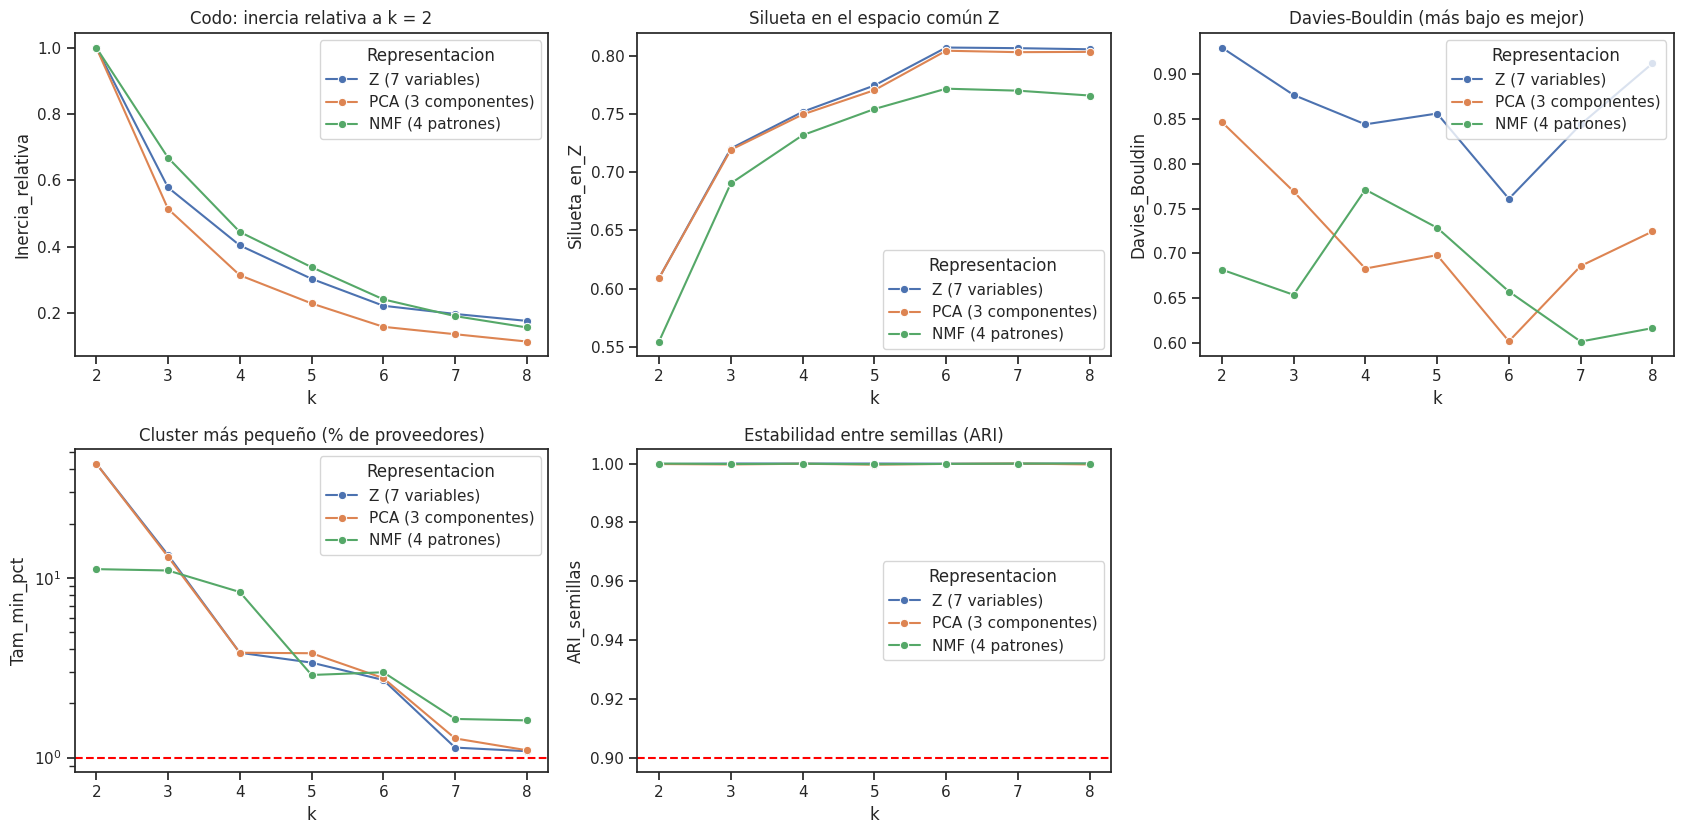

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
panel = [
    ("Inercia_relativa", "Codo: inercia relativa a k = 2", axes[0, 0]),
    ("Silueta_en_Z", "Silueta en el espacio común Z", axes[0, 1]),
    ("Davies_Bouldin", "Davies-Bouldin (más bajo es mejor)", axes[0, 2]),
    ("Tam_min_pct", "Cluster más pequeño (% de proveedores)", axes[1, 0]),
    ("ARI_semillas", "Estabilidad entre semillas (ARI)", axes[1, 1]),
]

for columna, titulo, ax in panel:
    # Al establecer legend=True, Seaborn generará una leyenda para cada iteración
    sns.lineplot(data=resultados_kmeans, x="k", y=columna, hue="Representacion", marker="o", ax=ax, legend=True)
    ax.set(title=titulo, xlabel="k")

axes[1, 0].axhline(1, color="red", linestyle="--")
axes[1, 0].set_yscale("log")
axes[1, 1].axhline(0.9, color="red", linestyle="--")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

**Regla de selección de k (definida antes de mirar los resultados).** Entre los valores de k que cumplen simultáneamente (1) cluster más pequeño de al menos 1 % de los proveedores y (2) estabilidad ARI de al menos 0,90, se elige el de mayor silueta en el espacio común Z.

In [ ]:
candidatos = resultados_kmeans[(resultados_kmeans["Tam_min_pct"] >= 1) & (resultados_kmeans["ARI_semillas"] >= 0.9)]
mejores = candidatos.loc[candidatos.groupby("Representacion")["Silueta_en_Z"].idxmax()].set_index("Representacion")

display(mejores[["k", "Silueta", "Silueta_en_Z", "Davies_Bouldin", "Calinski_Harabasz", "Tam_min_pct", "ARI_semillas"]].round(3))

,k,Silueta,Silueta_en_Z,Davies_Bouldin,Calinski_Harabasz,Tam_min_pct,ARI_semillas
Representacion,,,,,,,
NMF (4 patrones),6,0.790,0.772,0.657,73053.433,2.980,1.0
PCA (3 componentes),6,0.838,0.804,0.602,92127.307,2.764,1.0
Z (7 variables),6,0.807,0.807,0.761,58923.563,2.699,1.0


**Qué muestran los gráficos.**

- **Codo:** la inercia cae con fuerza hasta k = 6 y luego se aplana (en PCA, de 0,228 con k = 5 a 0,158 con k = 6 y 0,136 con k = 7).
- **Silueta en el espacio común Z:** sube hasta k = 6 y queda estable en k = 7 (Z: 0,807 y 0,806; PCA: 0,804 y 0,803; NMF: 0,772 y 0,770). Agregar un séptimo cluster no mejora la separación.
- **Davies-Bouldin:** el mínimo está en k = 6 para Z (0,761) y para PCA (0,602); sube en k = 7 (0,844 y 0,686). NMF es la excepción (0,657 con k = 6 y 0,601 con k = 7), pero su silueta común no mejora con el séptimo cluster.
- **Tamaño del cluster más pequeño:** con k = 6 es de 2,7 % (Z), 2,8 % (PCA) y 3,0 % (NMF); con k = 7 baja a 1,1 %, 1,3 % y 1,6 %. Todas las soluciones cumplen el mínimo de 1 %.
- **Estabilidad:** el ARI entre semillas es mayor a 0,999 en todos los casos; el resultado no depende de la inicialización.

**Resultado de la regla:** k = 6 en las tres representaciones. La silueta de k = 6 y k = 7 casi empata (diferencia de 0,001 en Z y en PCA), y Davies-Bouldin y el tamaño mínimo refuerzan a k = 6.

**Las tres representaciones no son equivalentes.** En el espacio común Z, Z y PCA separan igual (0,807 y 0,804: diferencia de 0,003), y NMF queda más abajo (0,772). La silueta propia de PCA (0,838) es más alta solo porque se mide en un espacio de 3 dimensiones y no debe compararse con las otras.


**6.2 DBSCAN.** Se aplica sobre PCA, que tiene pocas dimensiones y evita que la distancia se diluya.

**Dato técnico:** más de la mitad de los proveedores tiene un perfil repetido, y DBSCAN con tantos puntos idénticos agota la memoria. Se resuelve trabajando con los **perfiles únicos** (21 776 de 47 281) y usando su cantidad de repeticiones como peso (`sample_weight`); el resultado es equivalente a ejecutarlo sobre todos los proveedores.

**Parámetros evaluados:**

- `min_samples` = 10, 50 y 200 (0,02 %, 0,1 % y 0,4 % de los proveedores): cuántos proveedores debe tener una zona para considerarse densa.
- `eps` = 0,1; 0,2; 0,3 y 0,5: radio del vecindario en el espacio PCA, donde los componentes tienen desviaciones estándar entre 0,9 y 1,8.

**Regla de selección:** entre las combinaciones con ruido menor o igual a 5 %, la de mayor silueta (calculada sin los puntos de ruido).


In [ ]:
perfiles_unicos, indice_inverso, repeticiones = np.unique(np.round(Z_pca, 6), axis=0, return_inverse=True, return_counts=True)
indice_inverso = indice_inverso.ravel()
print("Perfiles únicos:", len(perfiles_unicos), "de", len(Z_pca), "proveedores")

filas = []
etiquetas_dbscan = {}
for min_muestras in [10, 50, 200]:
    for eps in [0.1, 0.2, 0.3, 0.5]:
        lab_unicos = DBSCAN(eps=eps, min_samples=min_muestras).fit_predict(perfiles_unicos, sample_weight=repeticiones)
        lab = lab_unicos[indice_inverso]
        etiquetas_dbscan[(min_muestras, eps)] = lab

        validos = lab >= 0
        tamanos = np.bincount(lab[validos])
        fila = {
            "min_samples": min_muestras, "eps": eps,
            "N_clusters": len(tamanos),
            "Clusters_de_1pct_o_mas": int((100 * tamanos / len(lab) >= 1).sum()),
            "Ruido_pct": 100 * (~validos).mean(),
            "Mayor_cluster_pct": 100 * tamanos.max() / len(lab),
            "Silueta_sin_ruido": np.nan,
        }
        if len(tamanos) > 1:
            fila["Silueta_sin_ruido"] = metricas_particion(Z_pca[validos], lab[validos])["Silueta"]
        filas.append(fila)
resultados_dbscan = pd.DataFrame(filas)
display(resultados_dbscan.round(3))

Perfiles únicos: 21776 de 47281 proveedores


,min_samples,eps,N_clusters,Clusters_de_1pct_o_mas,Ruido_pct,Mayor_cluster_pct,Silueta_sin_ruido
0,10,0.1,47,6,7.140,46.382,0.713
1,10,0.2,18,4,2.178,46.382,0.700
2,10,0.3,11,5,1.011,46.382,0.705
3,10,0.5,4,4,0.393,55.650,0.695
4,50,0.1,10,3,14.740,46.382,0.855
5,50,0.2,8,4,7.828,46.382,0.792
6,50,0.3,5,4,5.025,46.382,0.766
7,50,0.5,4,4,1.796,55.564,0.718
8,200,0.1,5,3,21.876,46.382,0.969
9,200,0.2,6,3,15.196,46.382,0.905


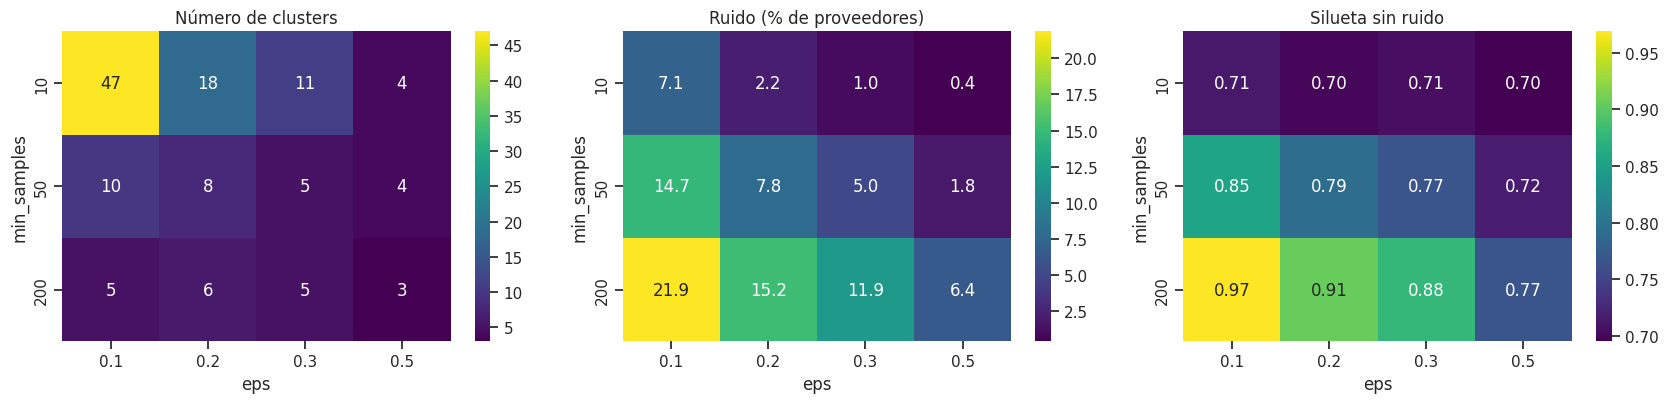

Configuración elegida: 50 min_samples y eps = 0.5


,min_samples,eps,N_clusters,Clusters_de_1pct_o_mas,Ruido_pct,Mayor_cluster_pct,Silueta_sin_ruido
7,50.0,0.5,4.0,4.0,1.796,55.564,0.718


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, columna, titulo, formato in [
    (axes[0], "N_clusters", "Número de clusters", ".0f"),
    (axes[1], "Ruido_pct", "Ruido (% de proveedores)", ".1f"),
    (axes[2], "Silueta_sin_ruido", "Silueta sin ruido", ".2f"),
]:
    tabla = resultados_dbscan.pivot(index="min_samples", columns="eps", values=columna)
    sns.heatmap(tabla, annot=True, fmt=formato, cmap="viridis", ax=ax)
    ax.set(title=titulo)
plt.tight_layout()
plt.show()

elegibles = resultados_dbscan[resultados_dbscan["Ruido_pct"] <= 5]
config_dbscan = elegibles.loc[elegibles["Silueta_sin_ruido"].idxmax()]
print("Configuración elegida:", int(config_dbscan["min_samples"]), "min_samples y eps =", config_dbscan["eps"])
display(config_dbscan.to_frame().T.round(3))

**Qué muestran los mapas de calor.**

- Con más `min_samples` y menos `eps` aparece más ruido (hasta 21,9 % de los proveedores con `min_samples` = 200 y `eps` = 0,1), y la silueta sube (hasta 0,97) solo porque se descartan los proveedores de frontera: no es una mejora real.
- En todas las combinaciones el cluster más grande tiene entre 46,4 % y 55,7 % de los proveedores: es el conjunto de los que no tienen adjudicación (perfiles idénticos de una convocatoria sin adjudicar y, con `eps` = 0,5, también los recurrentes sin adjudicación).
- Con ruido menor o igual a 5 % quedan cuatro combinaciones elegibles. La regla elige `min_samples` = 50 y `eps` = 0,5: 4 clusters, todos con 1 % o más de los proveedores (26 271; 18 782; 837 y 542), 1,8 % de ruido (849 proveedores) y silueta 0,718.
- **Sensibilidad de la regla:** con `min_samples` = 50 y `eps` = 0,3 el ruido es de 5,03 %, apenas sobre el límite, y se obtendrían 5 clusters con silueta 0,766. La elección depende del umbral de 5 % fijado de antemano.

**Lectura:** DBSCAN reconoce zonas densas y deja fuera lo que no pertenece a ninguna, pero con los parámetros que respetan el límite de ruido solo distingue dos grandes zonas (proveedores sin adjudicación y con adjudicación) y dos zonas pequeñas. Su cruce con los segmentos de K-means se muestra en la sección 7.


**6.3 Jerárquico.** Se aplica sobre PCA a una **muestra aleatoria de 8 000 proveedores** (con 47 281 filas la matriz de distancias no cabe en memoria). Se prueban dos enlaces, `ward` (minimiza la varianza dentro de cada grupo) y `average` (distancia promedio entre grupos), con k de 4 a 8. Para saber si K-means encontró una estructura real, se mide el ARI contra K-means sobre la misma muestra.


In [ ]:
k_pca = int(mejores.loc[f"PCA ({n_pca} componentes)", "k"])
etiquetas_km_pca = KMeans(n_clusters=k_pca, n_init=10, random_state=SEED).fit(Z_pca).labels_

muestra_jer = np.random.RandomState(SEED).choice(len(df), 8000, replace=False)
S = Z_pca[muestra_jer]

filas = []
for enlace in ["ward", "average"]:
    for k in range(4, 9):
        lab = AgglomerativeClustering(n_clusters=k, linkage=enlace).fit_predict(S)
        fila = {"Enlace": enlace, "k": k}
        fila.update(metricas_particion(S, lab))
        fila["Tam_min_pct"] = 100 * fila["Tam_min"] / len(S)
        fila["ARI_vs_KMeans"] = adjusted_rand_score(lab, etiquetas_km_pca[muestra_jer])
        filas.append(fila)
resultados_jer = pd.DataFrame(filas)
display(resultados_jer.drop(columns=["Tam_min", "Calinski_Harabasz"]).round(3))

,Enlace,k,Silueta,Davies_Bouldin,Tam_min_pct,ARI_vs_KMeans
0,ward,4,0.780,0.733,3.812,0.948
1,ward,5,0.817,0.697,3.812,0.982
2,ward,6,0.836,0.612,3.425,0.989
3,ward,7,0.833,0.703,1.188,0.987
4,ward,8,0.823,0.733,1.188,0.987
5,average,4,0.636,0.727,0.175,0.123
6,average,5,0.629,0.700,0.125,0.123
7,average,6,0.628,0.644,0.012,0.123
8,average,7,0.619,0.765,0.012,0.123
9,average,8,0.619,0.737,0.012,0.123


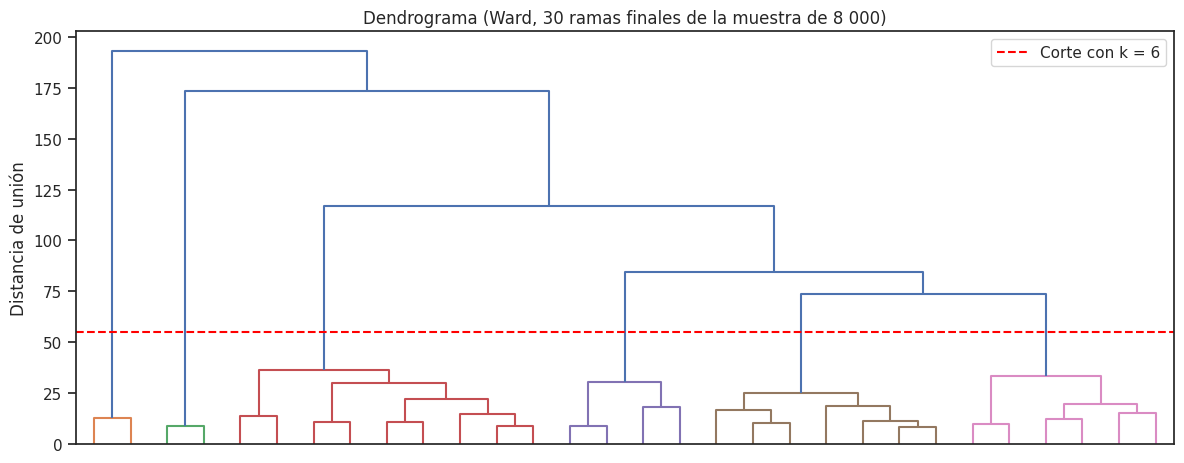

In [ ]:
enlaces = linkage(S, method="ward")
altura_corte = (enlaces[-k_pca, 2] + enlaces[-(k_pca - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(12, 4.8))
dendrogram(enlaces, truncate_mode="lastp", p=30, color_threshold=altura_corte, no_labels=True, ax=ax)
ax.axhline(altura_corte, color="red", linestyle="--", label=f"Corte con k = {k_pca}")
ax.set(title="Dendrograma (Ward, 30 ramas finales de la muestra de 8 000)", ylabel="Distancia de unión")
ax.legend()
plt.tight_layout()
plt.show()

**Qué muestran la tabla y el dendrograma.**

- **Ward** da resultados muy cercanos a K-means: con k = 6 la silueta es 0,836, Davies-Bouldin 0,612 y el ARI contra K-means 0,989. El ARI es el más alto precisamente en k = 6 (0,982 con k = 5, 0,987 con k = 7 y con k = 8), y cae a 0,948 con k = 4.
- **Average** produce clusters de entre 1 y 14 proveedores (0,01 % a 0,18 % de la muestra) y un ARI de 0,123 con K-means: el enlace promedio va "encadenando" proveedores vecinos y deja un cluster gigante. Se descarta.
- **Dendrograma:** el corte con k = 6 (línea roja, cerca de 55) deja seis grupos cuyas uniones internas ocurren por debajo de 37, mientras que las cinco últimas uniones entre grupos se dan entre 74 y 193. Los grupos están claramente separados antes de unirse.

**Conclusión:** un método independiente de K-means, sin inicialización aleatoria, encuentra casi la misma partición. Esto respalda que los 6 segmentos no son un artefacto del algoritmo.


**6.4 Comparación entre métodos.** Para cada método se toma su mejor configuración según la regla de su apartado. Las métricas de cada método se miden en su propio espacio y con su propio criterio, por eso la comparación más justa es el ARI: qué tanto coinciden los agrupamientos entre sí.

In [ ]:
fila_ward = resultados_jer[(resultados_jer["Enlace"] == "ward") & (resultados_jer["k"] == k_pca)].iloc[0]

filas = []
for nombre, fila in mejores.iterrows():
    filas.append({"Metodo": "K-means", "Configuracion": f"{nombre}, k = {int(fila['k'])}", "N_clusters": int(fila["k"]),
                  "Silueta": fila["Silueta"], "Davies_Bouldin": fila["Davies_Bouldin"], "Cluster_minimo_pct": fila["Tam_min_pct"], "Ruido_pct": 0.0})
filas.append({"Metodo": "DBSCAN", "Configuracion": f"PCA, min_samples = {int(config_dbscan['min_samples'])}, eps = {config_dbscan['eps']}",
              "N_clusters": int(config_dbscan["N_clusters"]), "Silueta": config_dbscan["Silueta_sin_ruido"], "Davies_Bouldin": np.nan,
              "Cluster_minimo_pct": np.nan, "Ruido_pct": config_dbscan["Ruido_pct"]})
filas.append({"Metodo": "Jerárquico (Ward, muestra de 8 000)", "Configuracion": f"PCA, k = {k_pca}", "N_clusters": k_pca,
              "Silueta": fila_ward["Silueta"], "Davies_Bouldin": fila_ward["Davies_Bouldin"], "Cluster_minimo_pct": fila_ward["Tam_min_pct"], "Ruido_pct": 0.0})
comparacion = pd.DataFrame(filas)
display(comparacion.round(3))

,Metodo,Configuracion,N_clusters,Silueta,Davies_Bouldin,Cluster_minimo_pct,Ruido_pct
0,K-means,"NMF (4 patrones), k = 6",6,0.790,0.657,2.980,0.000
1,K-means,"PCA (3 componentes), k = 6",6,0.838,0.602,2.764,0.000
2,K-means,"Z (7 variables), k = 6",6,0.807,0.761,2.699,0.000
3,DBSCAN,"PCA, min_samples = 50, eps = 0.5",4,0.718,NaN,NaN,1.796
4,"Jerárquico (Ward, muestra de 8 000)","PCA, k = 6",6,0.836,0.612,3.425,0.000


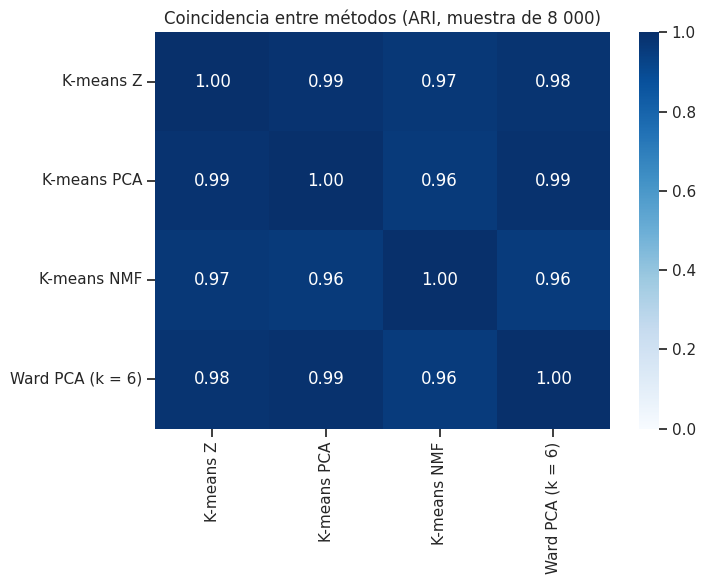

ARI de DBSCAN contra K-means PCA (sin ruido): 0.727


In [ ]:
etiq = {}
for nombre, X in representaciones.items():
    etiq["K-means " + nombre.split(" ")[0]] = KMeans(n_clusters=int(mejores.loc[nombre, "k"]), n_init=10, random_state=SEED).fit(X).labels_[muestra_jer]
etiq[f"Ward PCA (k = {k_pca})"] = AgglomerativeClustering(n_clusters=k_pca, linkage="ward").fit_predict(S)

nombres_met = list(etiq.keys())
ari = pd.DataFrame(
    [[adjusted_rand_score(etiq[a], etiq[b]) for b in nombres_met] for a in nombres_met], index=nombres_met, columns=nombres_met)

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set(title="Coincidencia entre métodos (ARI, muestra de 8 000)")
plt.tight_layout()
plt.show()

# DBSCAN se compara aparte porque deja proveedores sin cluster (ruido)
lab_db = etiquetas_dbscan[(int(config_dbscan["min_samples"]), config_dbscan["eps"])][muestra_jer]
sin_ruido = lab_db >= 0
print("ARI de DBSCAN contra K-means PCA (sin ruido):",
      round(adjusted_rand_score(lab_db[sin_ruido], etiquetas_km_pca[muestra_jer][sin_ruido]), 3))

**Cómo leer la tabla y el mapa de calor.**

- **K-means sobre PCA (k = 6)** y **Ward (k = 6)** obtienen resultados casi idénticos (silueta 0,838 y 0,836; Davies-Bouldin 0,602 y 0,612). K-means sobre Z (0,807) y sobre NMF (0,790) quedan algo por debajo; DBSCAN tiene la silueta más baja (0,718) y deja 1,8 % de proveedores sin cluster.
- **ARI entre métodos:** los tres K-means y Ward coinciden entre 0,96 y 0,99. La estructura que se encuentra no depende de la representación ni del algoritmo.
- **DBSCAN** coincide con K-means en 0,727 (sin contar el ruido): valor menor porque separa por resultado (ganó o no ganó) y une segmentos que K-means distingue por recurrencia (sección 7).

**Qué método sirve mejor para segmentar:** K-means. Entrega una partición completa (ningún proveedor queda sin segmento), estable, y confirmada por Ward. DBSCAN sirve de contraste: muestra qué segmentos son densos y cuáles son atípicos.


# <font color=green>7. Selección provisional y estabilidad</font>

**Solución provisional: K-means con k = 6 sobre PCA de 3 componentes.** Es provisional porque faltan validaciones del Hito 4 (sección 11). La elección se apoya en:

| Criterio | Evidencia |
|---|---|
| Separación | En el espacio común, PCA (0,804) equivale a las 7 variables (0,807) y supera a NMF (0,772) |
| Parsimonia | PCA usa 3 dimensiones en lugar de 7, no correlacionadas entre sí y con una lectura clara (actividad, eficacia, diversificación) |
| Número de clusters | k = 6 tiene el menor Davies-Bouldin (0,602), un cluster mínimo de 2,8 % y silueta igual a k = 7 |
| Estabilidad | ARI mayor a 0,999 entre semillas |
| Confirmación independiente | Ward con k = 6 coincide en 0,989 y obtiene su mayor ARI justo en k = 6 |


In [ ]:
representacion_final = f"PCA ({n_pca} componentes)"
k_final = k_pca
X_final = representaciones[representacion_final]

print("Solución provisional: K-means con k =", k_final, "sobre", representacion_final)

lab_base = KMeans(n_clusters=k_final, n_init=10, random_state=SEED).fit(X_final).labels_

ari_semillas = [adjusted_rand_score(lab_base, KMeans(n_clusters=k_final, n_init=10, random_state=s).fit(X_final).labels_)
                for s in [2, 3, 4, 5, 6]]

submuestra = np.random.RandomState(7).choice(len(df), 22000, replace=False)
modelo_sub = KMeans(n_clusters=k_final, n_init=10, random_state=SEED).fit(X_final[submuestra])
ari_submuestra = adjusted_rand_score(lab_base, modelo_sub.predict(X_final))

print("ARI contra otras 5 semillas (mínimo):", round(min(ari_semillas), 4))
print("ARI contra una submuestra de 22 000 proveedores:", round(ari_submuestra, 4))

Solución provisional: K-means con k = 6 sobre PCA (3 componentes)
ARI contra otras 5 semillas (mínimo): 0.9997
ARI contra una submuestra de 22 000 proveedores: 0.9998


**Numeración de los segmentos.** Los clusters se renumeran de menor a mayor número medio de convocatorias, para que la numeración no cambie entre ejecuciones.

,Proveedores
0,26271
1,18782
3,837
2,542


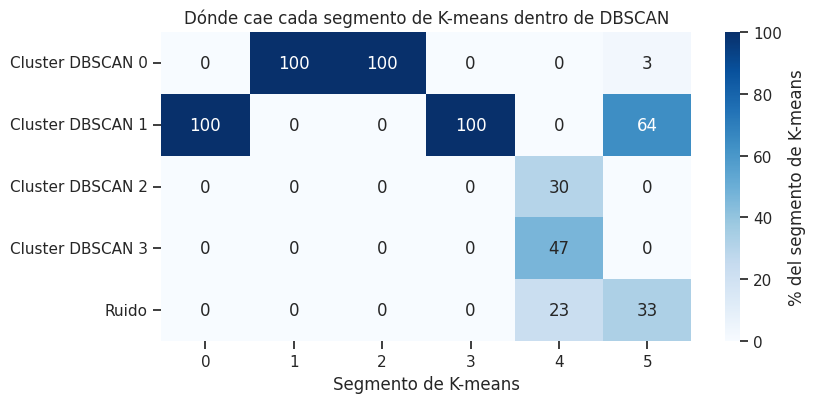

In [ ]:
d = df.copy()
d["cluster"] = lab_base

orden = d.groupby("cluster")["n_convocatorias"].mean().sort_values().index
d["cluster"] = d["cluster"].map({viejo: nuevo for nuevo, viejo in enumerate(orden)})

# DBSCAN elegido: los clusters de menos de 1 % se agrupan como "Otros" para poder leer el cruce
lab_db = etiquetas_dbscan[(int(config_dbscan["min_samples"]), config_dbscan["eps"])]
tam_db = pd.Series(lab_db[lab_db >= 0]).value_counts()
grandes_db = tam_db[tam_db / len(lab_db) >= 0.01].index

grupo_db = pd.Series(lab_db).map({c: f"Cluster DBSCAN {c}" for c in grandes_db}).fillna("Otros clusters pequeños")
grupo_db[lab_db == -1] = "Ruido"

cruce_db = pd.crosstab(grupo_db.values, d["cluster"].values, normalize="columns") * 100
display(tam_db.loc[grandes_db].rename("Proveedores").to_frame())

fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.heatmap(cruce_db, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "% del segmento de K-means"})
ax.set(title="Dónde cae cada segmento de K-means dentro de DBSCAN", xlabel="Segmento de K-means", ylabel="")
plt.tight_layout()
plt.show()



**Qué muestra el cruce** (cada columna suma 100 %: dónde cae cada segmento de K-means dentro de DBSCAN):

- El **cluster DBSCAN 0** (26 271 proveedores) contiene al 100 % de los segmentos 1 y 2: todos los proveedores sin adjudicación, tanto los de una sola vez como los recurrentes. DBSCAN no distingue la recurrencia dentro de ese grupo.
- El **cluster DBSCAN 1** (18 782) contiene al 100 % del segmento 0, al 99,8 % del 3 y al 64,0 % del 5: los proveedores que ganaron, sin importar si lo hicieron una vez o varias.
- Los **clusters 2 y 3** (542 y 837 proveedores) son dos zonas dentro del segmento 4: contienen al 30,3 % y al 46,9 % de los generalistas multirrubro.
- El **ruido** concentra a los perfiles más raros: el 33,1 % de los grandes operadores (5) y el 22,8 % de los generalistas multirrubro (4).

**Lectura:** con estos parámetros DBSCAN separa por resultado (ganó o no ganó) y no por recurrencia, y es ciego a los segmentos raros y a las diferencias graduales. Por eso no se usa como solución final.


,Silueta_media,Prop_negativa
cluster,,
0,0.921,0.000
1,0.973,0.000
2,0.535,0.003
3,0.368,0.033
4,0.446,0.000
5,0.327,0.113


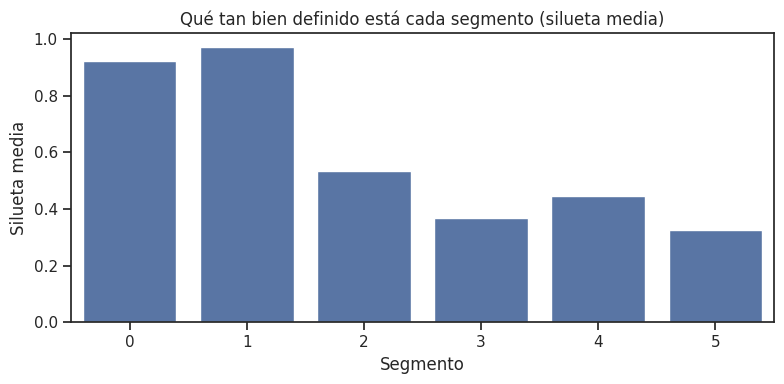

In [ ]:
# silueta de cada proveedor en la muestra común, para ver qué segmentos están mejor definidos
silueta_prov = pd.Series(silhouette_samples(X_final[muestra_z], d["cluster"].values[muestra_z]))
silueta_seg = pd.DataFrame({"cluster": d["cluster"].values[muestra_z], "silueta": silueta_prov.values})
resumen_sil = silueta_seg.groupby("cluster")["silueta"].agg(Silueta_media="mean", Prop_negativa=lambda s: (s < 0).mean())
display(resumen_sil.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=resumen_sil.index, y=resumen_sil["Silueta_media"], color="#4c72b0", ax=ax)
ax.set(title="Qué tan bien definido está cada segmento (silueta media)", xlabel="Segmento", ylabel="Silueta media")
plt.tight_layout()
plt.show()

**Estabilidad.** Repetir K-means con otras 5 semillas da un ARI mínimo de 0,9997, y asignar a todos los proveedores con un modelo entrenado en una submuestra de 22 000 da 0,9998: la partición se reproduce prácticamente igual.

**Qué tan bien definido está cada segmento** (silueta media; entre -1 y 1):

- **Segmentos 0 y 1 (0,92 y 0,97):** muy compactos, sin proveedores mal asignados. Son en buena parte perfiles idénticos.
- **Segmentos 2 y 4 (0,54 y 0,45):** bien definidos.
- **Segmento 3 (0,37):** 3,3 % de sus proveedores quedaría más cerca de otro segmento.
- **Segmento 5 (0,33):** el menos definido; 11,3 % de sus proveedores quedaría más cerca de otro segmento. Su frontera con los ganadores recurrentes es gradual: ser gran operador es más una cuestión de grado que una categoría separada.

Estos valores se usan para matizar la interpretación: las distinciones entre 0, 1 y 2 son nítidas; las que involucran a los segmentos 3 y 5 son aproximadas.


# <font color=green>8. Perfil de los segmentos</font>

Los segmentos se describen con las variables del modelo (en unidades originales). Las penalidades y el consorcio **no participaron en el modelo**: se muestran como lectura posterior.

In [ ]:
d["tiene_adjudicacion"] = (d["n_items_adjudicados"] > 0).astype(int)

perfil = d.groupby("cluster").agg(
    n_proveedores=("ruc_proveedor", "size"),
    conv_mediana=("n_convocatorias", "median"),
    conv_media=("n_convocatorias", "mean"),
    items_mediana=("n_items_adjudicados", "median"),
    prop_con_adjudicacion=("tiene_adjudicacion", "mean"),
    tasa_media=("tasa_adjudicacion", "mean"),
    monto_mediana=("monto_total_adjudicado", "median"),
    municip_mediana=("n_municipalidades", "median"),
    rubros_media=("n_rubros", "mean"),
    dias_mediana=("dias_trayectoria", "median"),
    prop_consorcio=("participa_en_consorcio", "mean"),
    prop_penalidades=("tiene_penalidades", "mean"),
    monto_total=("monto_total_adjudicado", "sum"),
)
perfil["porcentaje"] = 100 * perfil["n_proveedores"] / len(d)
perfil["pct_monto_total"] = 100 * perfil["monto_total"] / perfil["monto_total"].sum()
display(perfil.round(2))

,n_proveedores,conv_mediana,conv_media,items_mediana,prop_con_adjudicacion,tasa_media,monto_mediana,municip_mediana,rubros_media,dias_mediana,prop_consorcio,prop_penalidades,monto_total,porcentaje,pct_monto_total
cluster,,,,,,,,,,,,,,,
0,13950,1.0,1.05,1.0,1.00,0.99,230000.00,1.0,1.00,0.0,0.07,0.01,1.712e+10,29.50,67.58
1,22856,1.0,1.05,0.0,0.00,0.00,0.00,1.0,1.00,0.0,0.07,0.01,0.000e+00,48.34,0.00
2,3376,3.0,4.16,0.0,0.00,0.00,0.00,2.0,1.00,337.5,0.29,0.06,0.000e+00,7.14,0.00
3,4006,4.0,4.62,2.0,1.00,0.52,211284.41,2.0,1.00,529.5,0.31,0.06,3.243e+09,8.47,12.80
4,1786,5.0,7.47,1.0,0.66,0.30,126996.36,2.0,2.05,738.5,0.53,0.11,1.612e+09,3.78,6.36
5,1307,20.0,32.45,4.0,0.93,0.25,732368.30,8.0,1.02,1281.0,0.38,0.14,3.357e+09,2.76,13.25


In [ ]:
# concentración del monto adjudicado entre todos los proveedores
montos = df["monto_total_adjudicado"].sort_values(ascending=False)
for pct in [1, 5]:
    n = int(len(df) * pct / 100)
    print(f"El {pct} % de los proveedores ({n}) concentra {montos.head(n).sum() / montos.sum():.1%} del monto adjudicado")

El 1 % de los proveedores (472) concentra 41.9% del monto adjudicado
El 5 % de los proveedores (2364) concentra 72.5% del monto adjudicado


**Nombres de los segmentos** (se asignan después de leer el perfil de la tabla anterior y se validarán en el Hito 4). Cada nombre combina dos cosas: **cuánto participan** (una sola vez o de forma recurrente) y **qué resultado obtienen** (ganan o no), salvo los dos segmentos que se distinguen por otra característica (rubros y escala).

| Segmento | Nombre | Qué lo define en el perfil |
|---|---|---|
| 0 | **Ganadores de una sola vez** | 1 convocatoria y la ganó (tasa media 0,99), 1 municipalidad, 0 días de trayectoria; monto mediano de S/ 230 000 |
| 1 | **Postores de una sola vez sin éxito** | 1 convocatoria, ninguna adjudicación, 1 municipalidad, 0 días |
| 2 | **Postores recurrentes sin éxito** | Mediana de 3 convocatorias en 2 municipalidades durante unos 338 días, ninguna adjudicación |
| 3 | **Ganadores recurrentes** | Mediana de 4 convocatorias y 2 ítems adjudicados; todos adjudicaron al menos una vez (tasa media 0,52); monto mediano de S/ 211 284 |
| 4 | **Generalistas multirrubro** | 2,05 rubros en promedio frente a 1,0 de los demás; 66 % con adjudicación |
| 5 | **Grandes operadores multimunicipales** | Mediana de 20 convocatorias en 8 municipalidades durante 1 281 días; 93,5 % con adjudicación, pero con tasa media de solo 0,25 |


In [ ]:
nombres_segmentos = {
    0: "Seg.1 Ganadores de una sola vez",
    1: "Seg.2 Postores de una sola vez sin éxito",
    2: "Seg.3 Postores recurrentes sin éxito",
    3: "Seg.4 Ganadores recurrentes",
    4: "Seg.5 Generalistas multirrubro",
    5: "Seg.6 Grandes operadores multimunicipales",
}

d["segmento"] = d["cluster"].map(nombres_segmentos)
perfil.index = perfil.index.map(nombres_segmentos)

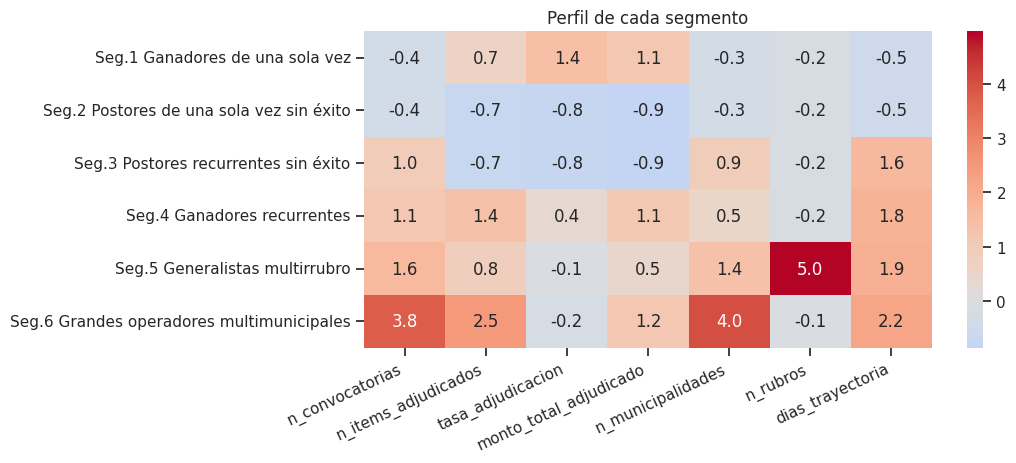

In [ ]:
# promedio de cada variable estandarizada por segmento: positivo = por encima del promedio general
centros = pd.DataFrame(X_z, columns=variables).groupby(d["segmento"].values).mean()

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(centros, annot=True, fmt=".1f", cmap="coolwarm", center=0, ax=ax)
ax.set(title="Perfil de cada segmento", xlabel="", ylabel="")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

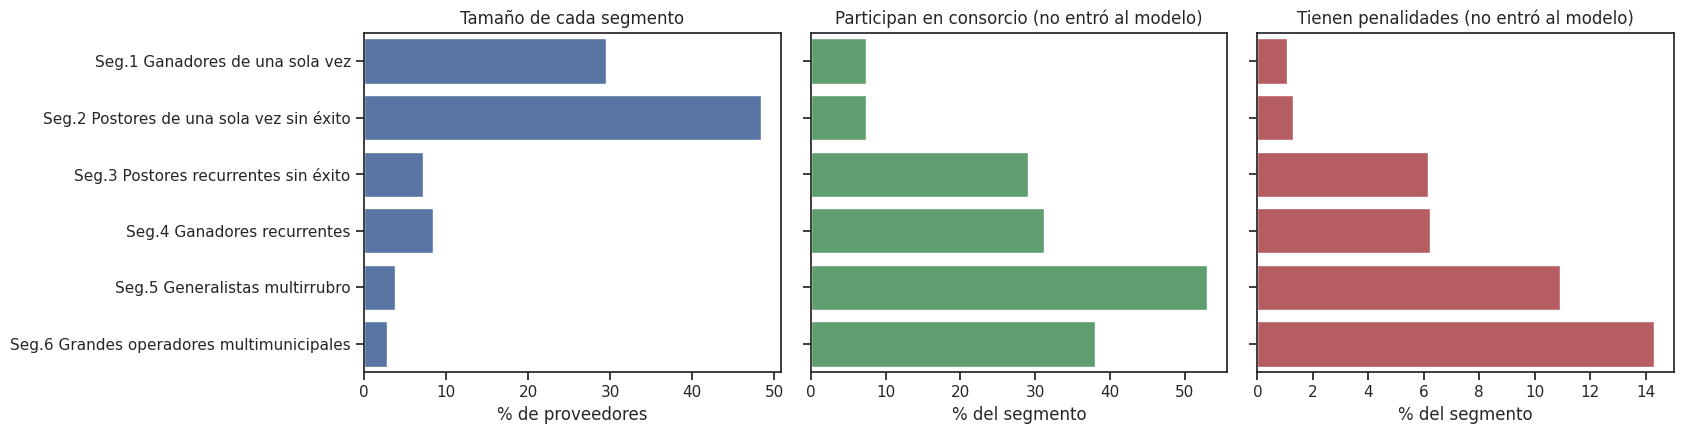

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)

sns.barplot(y=perfil.index, x=perfil["porcentaje"], color="#4c72b0", ax=axes[0])
axes[0].set(title="Tamaño de cada segmento", xlabel="% de proveedores", ylabel="")

sns.barplot(y=perfil.index, x=100 * perfil["prop_consorcio"], color="#55a868", ax=axes[1])
axes[1].set(title="Participan en consorcio (no entró al modelo)", xlabel="% del segmento", ylabel="")

sns.barplot(y=perfil.index, x=100 * perfil["prop_penalidades"], color="#c44e52", ax=axes[2])
axes[2].set(title="Tienen penalidades (no entró al modelo)", xlabel="% del segmento", ylabel="")

plt.tight_layout()
plt.show()

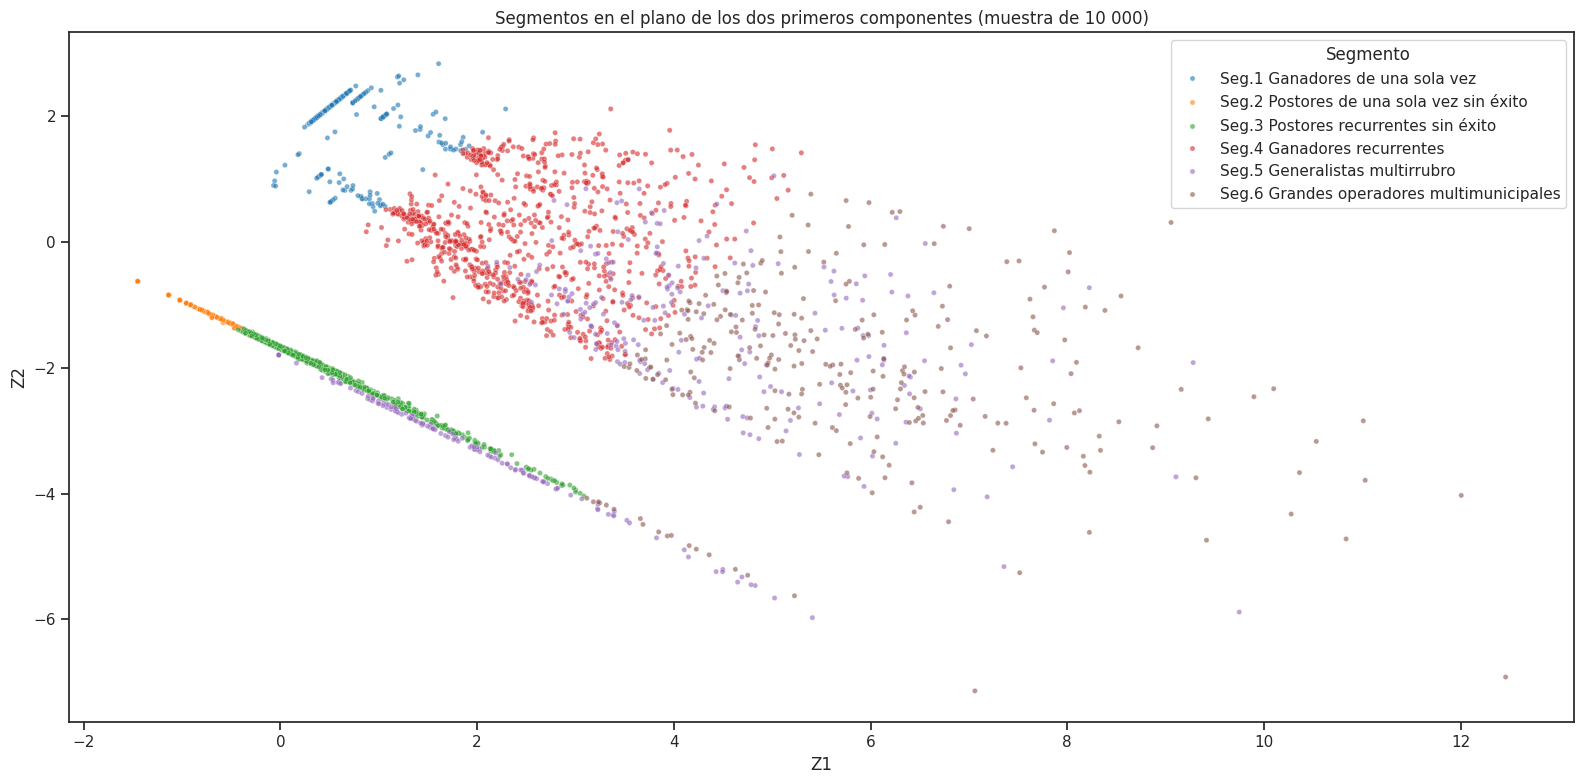

In [ ]:
Z_graf = pd.DataFrame(Z_pca[:, :2], columns=["Z1", "Z2"])
Z_graf["Segmento"] = d["segmento"].values
Z_graf = Z_graf.sample(10000, random_state=SEED).sort_values("Segmento")

fig, ax = plt.subplots(figsize=(16, 8))
sns.scatterplot(data=Z_graf, x="Z1", y="Z2", hue="Segmento", palette="tab10", s=14, alpha=0.6, ax=ax)
ax.set(title="Segmentos en el plano de los dos primeros componentes (muestra de 10 000)")
plt.tight_layout()
plt.show()



- **Ganadores de una sola vez (0) y postores de una sola vez sin éxito (1):** idénticos en participación (convocatorias -0,42, días -0,51) y opuestos en resultado: el 0 tiene tasa +1,40 y monto +1,13; el 1 tiene tasa -0,78 y monto -0,86. La única diferencia es haber ganado o no.
- **Postores recurrentes sin éxito (2) y ganadores recurrentes (3):** misma recurrencia (convocatorias +0,96 y +1,12; días +1,61 y +1,81), y de nuevo se distinguen por el resultado: el 2 nunca ganó (ítems -0,73) y el 3 sí (ítems +1,35).
- **Generalistas multirrubro (4):** `n_rubros` en +5,0 desviaciones estándar; es el único que diversifica.
- **Grandes operadores multimunicipales (5):** convocatorias +3,76 y municipalidades +4,03; operan en muchos lugares y por mucho tiempo. Su tasa de adjudicación es ligeramente baja (-0,23): participan en muchas convocatorias y ganan una fracción.

**Tamaño y monto.** Los segmentos 0 y 1 reúnen al 78 % de los proveedores (29,5 % y 48,3 %); los recurrentes (2 a 5) son el 22 %. Los grandes operadores son el 2,76 % de los proveedores. En el monto adjudicado, en cambio, los **ganadores de una sola vez concentran el 67,6 %** del total, y los grandes operadores solo el 13,3 %. Esto indica que el dinero se concentra en pocos contratos grandes ganados en una sola participación, no en proveedores recurrentes: el 1 % de los proveedores (472) concentra 41,9 % del monto y el 5 % (2 364) concentra 72,5 %.

**Lo que no entró al modelo.** El **consorcio** pasa de 7 % en los segmentos 0 y 1 a 29-31 % en los recurrentes (2 y 3), 53 % en los generalistas multirrubro y 38 % en los grandes operadores. Las **penalidades** crecen con la actividad: 1 % en los segmentos 0 y 1, 6 % en 2 y 3, 11 % en 4 y 14 % en 5. Es una lectura descriptiva: quien participa más tiene más oportunidades de ser penalizado, por lo que falta medir la tasa por contrato (sección 11).


# <font color=green>9. Distribución territorial (provincias)</font>

El proyecto analiza municipalidades provinciales, por lo que el territorio se mapea por **provincia**. Con la matriz completa, las **196 provincias** tienen datos, incluida la provincia de Lima (Municipalidad Metropolitana de Lima). Cada proveedor aparece en todas las provincias donde participó (`provincias_participacion` tiene una provincia por cada municipalidad). Por eso los conteos suman más que los 47 281 proveedores.

Los límites provinciales vienen del repositorio clonado `limites-peru-geojson`, archivo `LIM_PROVINCIAL_PERU.json`.

**Cómo usar el mapa interactivo (Plotly):** el menú desplegable de la esquina superior izquierda cambia lo que se pinta (volumen de proveedores o peso de un segmento); al pasar el cursor sobre una provincia aparece su nombre, departamento y valores; la rueda del ratón hace zoom, arrastrar mueve el mapa y el ícono de cámara descarga la vista como imagen. Las provincias en gris tienen menos de 100 proveedores y no se pintan en los mapas de porcentaje.


In [ ]:
limites = gpd.read_file("limites-peru-geojson/LIM_PROVINCIAL_PERU.json")

# el archivo trae 'CAÑETE' y 'FERREÑAFE' con un carácter dañado tras la N, y 'NASCA' en lugar de 'NAZCA'
limites["provincia"] = limites["NOMBPROV"].str.replace("\x91", "").map(normalizar_texto).replace({"NASCA": "NAZCA"})

provincias = d[["ruc_proveedor", "segmento", "provincias_participacion"]].copy()
provincias["provincia"] = provincias["provincias_participacion"].str.split(",")
provincias = provincias.explode("provincia").reset_index(drop=True)
provincias["provincia"] = provincias["provincia"].map(normalizar_texto)
provincias = provincias.drop_duplicates(["ruc_proveedor", "provincia"])

print("Provincias en los datos:", provincias["provincia"].nunique(), "| en el mapa:", limites["provincia"].nunique())
print("Sin cruce en el mapa:", sorted(set(provincias["provincia"]) - set(limites["provincia"])))
print("Provincias del mapa sin proveedores:", sorted(set(limites["provincia"]) - set(provincias["provincia"])))

Provincias en los datos: 196 | en el mapa: 196
Sin cruce en el mapa: []
Provincias del mapa sin proveedores: []


In [ ]:
tabla_prov = pd.crosstab(provincias["provincia"], provincias["segmento"])
tabla_prov["total"] = tabla_prov.sum(axis=1)

apariciones = tabla_prov.drop(columns="total").sum()
peso = pd.DataFrame({"pct_de_proveedores": perfil["porcentaje"], "pct_de_apariciones_en_provincias": 100 * apariciones / apariciones.sum()})
print("Apariciones proveedor-provincia:", int(apariciones.sum()), "| provincias por proveedor (promedio):", round(apariciones.sum() / len(d), 2))
display(peso.round(1))

MIN_PROVEEDORES = 100   # con menos proveedores, el porcentaje de un segmento pequeño es muy inestable
porcentajes = tabla_prov.drop(columns="total").div(tabla_prov["total"], axis=0) * 100
porcentajes[tabla_prov["total"] < MIN_PROVEEDORES] = np.nan

mapa = limites.merge(tabla_prov[["total"]], left_on="provincia", right_index=True, how="left")
mapa = mapa.merge(porcentajes, left_on="provincia", right_index=True, how="left")

import numpy as np

cortes = [0, 50, 100, 200, 400, 800, np.inf]
rotulos = ["Menos de 50", "50 a 99", "100 a 199", "200 a 399", "400 a 799", "800 o más"]
mapa["rango_proveedores"] = pd.cut(mapa["total"], bins=cortes, labels=rotulos, right=False)

mapa["pct_recurrentes"] = mapa[[nombres_segmentos[i] for i in (2, 3, 4, 5)]].sum(axis=1, min_count=1)

print("Provincias con al menos", MIN_PROVEEDORES, "proveedores:", int((tabla_prov["total"] >= MIN_PROVEEDORES).sum()), "de", len(tabla_prov))

Apariciones proveedor-provincia: 74244 | provincias por proveedor (promedio): 1.57


,pct_de_proveedores,pct_de_apariciones_en_provincias
Seg.1 Ganadores de una sola vez,29.5,18.8
Seg.2 Postores de una sola vez sin éxito,48.3,30.8
Seg.3 Postores recurrentes sin éxito,7.1,11.0
Seg.4 Ganadores recurrentes,8.5,10.4
Seg.5 Generalistas multirrubro,3.8,8.3
Seg.6 Grandes operadores multimunicipales,2.8,20.6


Provincias con al menos 100 proveedores: 177 de 196


In [ ]:
import plotly.graph_objects as go
import json

# 1. Copia del mapa y simplificación
mapa_geo = mapa.copy()
mapa_geo["geometry"] = mapa_geo.geometry.simplify(0.02, preserve_topology=True).set_precision(0.001)

# --- CORRECCIÓN PARA LIMA ---
# Creamos un ID único combinando Departamento y Provincia para evitar que Plotly se confunda
mapa_geo["id_provincia"] = mapa_geo["NOMBDEP"] + "_" + mapa_geo["provincia"]

# Usamos este nuevo ID único como index para el geojson de provincias
geojson = json.loads(mapa_geo.set_index("id_provincia")[["geometry"]].to_json())

# Para los departamentos, NOMBDEP suele ser único, así que está bien
deptos = mapa_geo[["NOMBDEP", "geometry"]].dissolve(by="NOMBDEP").reset_index()
geojson_deptos = json.loads(deptos.set_index("NOMBDEP")[["geometry"]].to_json())

# 2. Punto interior de cada provincia, donde termina la línea de la etiqueta
puntos = mapa_geo.geometry.representative_point()
mapa_geo["lon"] = puntos.x
mapa_geo["lat"] = puntos.y

# 3. Cada opción del menú: columna, texto del título, escala de color y título de la barra
opciones = [
    ("indice_rango", "Proveedores que participaron por provincia", "YlOrRd", "Proveedores"),
    (nombres_segmentos[0], "Ganadores de una sola vez: % de los proveedores de la provincia", "Blues", "% del total"),
    (nombres_segmentos[1], "Postores de una sola vez sin éxito: % de los proveedores de la provincia", "Purples", "% del total"),
    ("pct_recurrentes", "Proveedores recurrentes (segmentos 2 a 5): % de los proveedores de la provincia", "YlOrRd", "% del total"),
    (nombres_segmentos[5], "Grandes operadores multimunicipales: % de los proveedores de la provincia", "Reds", "% del total"),
]

mapa_geo["indice_rango"] = mapa_geo["rango_proveedores"].cat.codes.where(mapa_geo["total"].notna())
datos_hover = mapa_geo[["NOMBDEP", "total"]].copy()
datos_hover["total"] = datos_hover["total"].fillna(0).astype(int)

fig = go.Figure()

# 4. Capa base gris para provincias sin datos
fig.add_trace(go.Choropleth(
    geojson=geojson,
    locations=mapa_geo["id_provincia"], # <- Usar ID único
    z=[0] * len(mapa_geo),              # <- Corrección de sintaxis
    colorscale=[[0, "lightgrey"], [1, "lightgrey"]],
    showscale=False,
    marker_line_width=0.3,
    marker_line_color="white",
    hoverinfo="skip"
))

# 5. Capas Coropléticas interactivas
for k, (columna, titulo, escala, titulo_barra) in enumerate(opciones):
    if columna == "indice_rango":
        barra = dict(title=titulo_barra, tickvals=list(range(len(rotulos))), ticktext=rotulos, len=0.6, thickness=15)
        plantilla = "<b>%{text}</b> (%{customdata[0]})<br>Proveedores que participaron: %{customdata[1]}<extra></extra>"
        zmin, zmax = 0, len(rotulos) - 1 # <- Corrección de sintaxis
    else:
        barra = dict(title=titulo_barra, len=0.6, thickness=15)
        plantilla = ("<b>%{text}</b> (%{customdata[0]})<br>Proveedores que participaron: %{customdata[1]}"
                     "<br>Peso del segmento: %{z:.1f} %<extra></extra>")
        zmin, zmax = 0, mapa_geo[columna].quantile(0.95)

    fig.add_trace(go.Choropleth(
        geojson=geojson,
        locations=mapa_geo["id_provincia"], # <- Usar ID único
        z=mapa_geo[columna],
        text=mapa_geo["NOMBPROV"],
        customdata=datos_hover.values,
        hovertemplate=plantilla,
        colorscale=escala,
        colorbar=barra,
        zmin=zmin,
        zmax=zmax,
        marker_line_width=0.3,
        marker_line_color="white",
        visible=(k == 0)
    ))

# 6. Etiquetas fuera del mapa (Top 10)
# Corrección de la lista de coordenadas Y
y_slots = [-1 - 4.125 * i for i in range(5)]

for k, (columna, titulo, escala, titulo_barra) in enumerate(opciones):
    campo = "total" if columna == "indice_rango" else columna
    top = mapa_geo.nlargest(10, campo).sort_values("lon")
    lons, lats, textos, tamanos, posiciones = [], [], [], [], []

    for grupo, lon_etiqueta, pos in [(top.iloc[:5], -84, "middle left"), (top.iloc[5:], -64, "middle right")]:
        grupo = grupo.sort_values("lat", ascending=False)
        for (_, fila), y in zip(grupo.iterrows(), y_slots):
            valor = f"{int(fila[campo])}" if columna == "indice_rango" else f"{fila[campo]:.1f} %"
            lons += [fila["lon"], lon_etiqueta, None]
            lats += [fila["lat"], y, None]
            textos += ["", f"<b>{fila['NOMBPROV']}</b><br>{valor}", ""]
            tamanos += [5, 0, 0]
            posiciones += ["middle center", pos, "middle center"]

    fig.add_trace(go.Scattergeo(
        lon=lons, lat=lats, mode="lines+markers+text", text=textos,
        textposition=posiciones, textfont=dict(size=11, color="#222222"),
        line=dict(color="#777777", width=1), marker=dict(size=tamanos, color="black"),
        hoverinfo="skip", showlegend=False, visible=(k == 0)
    ))

# 7. Contorno de departamentos encima de todo
fig.add_trace(go.Choropleth(
    geojson=geojson_deptos,
    locations=deptos["NOMBDEP"],
    z=[0] * len(deptos), # <- Corrección de sintaxis
    colorscale=[[0, "rgba(0,0,0,0)"], [1, "rgba(0,0,0,0)"]],
    showscale=False,
    marker_line_width=1.2,
    marker_line_color="#333333",
    hoverinfo="skip"
))

# 8. Menú de botones
n = len(opciones)
botones = []
for k, (columna, titulo, escala, titulo_barra) in enumerate(opciones):
    # Hay 1 capa base + n capas Choropleth + n capas Scattergeo + 1 capa contorno departamentos
    visibles = [True] + [j == k for j in range(n)] + [j == k for j in range(n)] + [True]
    botones.append(dict(
        label=titulo.split(":")[0],
        method="update",
        args=[{"visible": visibles}, {"title": {"text": titulo}}]
    ))

# 9. Configuración del layout y ejes geográficos
fig.update_geos(
    visible=False, lonaxis_range=[-93, -57], lataxis_range=[-19.5, 1],
    showland=True, landcolor="#f4f4f4", showocean=True, oceancolor="#e6f0f7",
    showcountries=True, countrycolor="#bbbbbb"
)

fig.update_layout(
    height=720, margin=dict(l=0, r=0, t=70, b=0),
    title={"text": opciones[0][1]},
    template="plotly_white", hoverlabel=dict(bgcolor="white", font_size=13),
    updatemenus=[dict(
        buttons=botones, direction="down", x=0.01, y=1.0,
        xanchor="left", yanchor="top"
    )]
)

fig.show()

In [ ]:
print("Provincias con más proveedores:")
display(mapa[["NOMBDEP", "provincia", "total"]].sort_values("total", ascending=False).head(5).reset_index(drop=True))

# provincias donde cada tipo de proveedor pesa más
for columna in [nombres_segmentos[5], nombres_segmentos[0], "pct_recurrentes"]:
    tabla = mapa[["NOMBDEP", "provincia", "total", columna]].dropna().sort_values(columna, ascending=False)
    print("Mayor peso de:", columna)
    display(tabla.head(5).round(1).reset_index(drop=True))
    print("Menor peso de:", columna)
    display(tabla.tail(5).round(1).reset_index(drop=True))

Provincias con más proveedores:


,NOMBDEP,provincia,total
0,LIMA,LIMA,2319
1,CUSCO,ESPINAR,1808
2,ANCASH,SANTA,1347
3,CUSCO,CANCHIS,1297
4,CAJAMARCA,CAJAMARCA,1240


Mayor peso de: Seg.6 Grandes operadores multimunicipales


,NOMBDEP,provincia,total,Seg.6 Grandes operadores multimunicipales
0,PUNO,MOHO,166,45.8
1,APURIMAC,GRAU,168,44.0
2,JUNIN,JAUJA,134,43.3
3,LIMA,OYON,115,41.7
4,JUNIN,JUNIN,127,40.9


Menor peso de: Seg.6 Grandes operadores multimunicipales


,NOMBDEP,provincia,total,Seg.6 Grandes operadores multimunicipales
0,ANCASH,MARISCAL LUZURIAGA,129,7.8
1,ANCASH,HUARI,633,7.4
2,ANCASH,CARLOS FERMIN FITZCARRALD,216,6.9
3,ANCASH,OCROS,160,6.9
4,ANCASH,SIHUAS,244,4.9


... (4 outputs left out)

Mayor peso de: pct_recurrentes


,NOMBDEP,provincia,total,pct_recurrentes
0,JUNIN,CHUPACA,203,79.8
1,APURIMAC,GRAU,168,78.6
2,APURIMAC,ABANCAY,578,76.0
3,CUSCO,CUSCO,1200,73.7
4,CUSCO,URUBAMBA,543,73.7


Menor peso de: pct_recurrentes


,NOMBDEP,provincia,total,pct_recurrentes
0,AMAZONAS,LUYA,275,30.2
1,ANCASH,AIJA,126,29.4
2,ANCASH,HUARI,633,29.2
3,ANCASH,CARLOS FERMIN FITZCARRALD,216,27.8
4,ANCASH,OCROS,160,27.5


In [ ]:
# la provincia de Lima (Municipalidad Metropolitana) frente a las demás provincias con 100 proveedores o más
comparables = porcentajes.dropna()
comparables = comparables.assign(recurrentes_2_a_5=comparables[[nombres_segmentos[i] for i in (2, 3, 4, 5)]].sum(axis=1))
lima = comparables.loc["LIMA"]

tabla_lima = pd.DataFrame({
    "Lima_pct": lima,
    "Mediana_provincias_pct": comparables.median(),
    "Puesto_de_Lima": [int((comparables[c] > lima[c]).sum() + 1) for c in comparables.columns],
})
display(tabla_lima.round(1))
print("Provincias comparables (100 proveedores o más):", len(comparables))

# proveedores que participaron solo en Lima
n_prov_por_proveedor = provincias.groupby("ruc_proveedor")["provincia"].nunique()
en_lima = provincias.loc[provincias["provincia"] == "LIMA", "ruc_proveedor"]
solo_lima = en_lima[en_lima.map(n_prov_por_proveedor) == 1]
print(f"Proveedores en Lima: {len(en_lima)} | participan solo en Lima: {len(solo_lima)} ({len(solo_lima) / len(en_lima):.1%})")
print("Segmento de los que participan solo en Lima:")
display(d.loc[d["ruc_proveedor"].isin(solo_lima), "segmento"].value_counts(normalize=True).mul(100).round(1).to_frame("%"))


,Lima_pct,Mediana_provincias_pct,Puesto_de_Lima
segmento,,,
Seg.1 Ganadores de una sola vez,9.8,22.0,153
Seg.2 Postores de una sola vez sin éxito,49.2,27.3,4
Seg.3 Postores recurrentes sin éxito,13.7,10.1,22
Seg.4 Ganadores recurrentes,10.1,10.0,88
Seg.5 Generalistas multirrubro,7.4,7.3,87
Seg.6 Grandes operadores multimunicipales,9.8,20.1,165
recurrentes_2_a_5,41.1,48.3,130


Provincias comparables (100 proveedores o más): 177
Proveedores en Lima: 2319 | participan solo en Lima: 1527 (65.8%)
Segmento de los que participan solo en Lima:


,%
segmento,
Seg.2 Postores de una sola vez sin éxito,74.5
Seg.1 Ganadores de una sola vez,14.9
Seg.4 Ganadores recurrentes,5.2
Seg.3 Postores recurrentes sin éxito,3.9
Seg.5 Generalistas multirrubro,1.4
Seg.6 Grandes operadores multimunicipales,0.1



**Volumen de proveedores.** La mediana es de 246 proveedores por provincia, con un rango de 18 (Putumayo) a 2 319 (Lima). Las provincias con más proveedores son **Lima (2 319)**, Espinar (Cusco, 1 808), Santa (Áncash, 1 347), Canchis (Cusco, 1 297) y Cajamarca (1 240). Hay 2 provincias con menos de 50 proveedores, 17 con 50 a 99, 53 con 100 a 199, 57 con 200 a 399, 48 con 400 a 799 y 18 con 800 o más. Con esta matriz no se puede explicar qué origina las diferencias de volumen (presupuesto de inversión, tamaño de la provincia, entre otros).

**Peso de los segmentos.** Los mapas de porcentaje solo incluyen las 177 provincias con al menos 100 proveedores, porque un porcentaje calculado sobre pocas decenas de proveedores es inestable.

Un dato para interpretarlos: los grandes operadores multimunicipales son el 2,76 % de los proveedores, pero representan el 20,6 % de las apariciones proveedor-provincia, porque cada uno opera en 8 municipalidades en mediana. Por eso su peso por provincia (5 % a 46 %) es mucho mayor que su peso en el padrón.

| Segmento | Provincias donde más pesa | Provincias donde menos pesa |
|---|---|---|
| Grandes operadores multimunicipales | Moho (Puno) 45,8 %, Grau (Apurímac) 44,0 %, Jauja (Junín) 43,3 %, Oyón (departamento de Lima) 41,7 % | Sihuas 4,9 %, Ocros 6,9 %, Carlos Fermín Fitzcarrald 6,9 %, Huari 7,4 % (todas en Áncash) |
| Ganadores de una sola vez | Sucre (Ayacucho) 49,3 %, Huari (Áncash) 47,6 %, Carlos Fermín Fitzcarrald (Áncash) 46,3 %, Atalaya (Ucayali) 42,9 % | Canchis 5,0 %, Calca 5,4 %, Acomayo 5,7 %, Quispicanchi 6,4 % (Cusco), Abancay 5,2 % |
| Recurrentes (2 a 5) | Chupaca (Junín) 79,8 %, Grau (Apurímac) 78,6 %, Abancay 76,0 %, Cusco 73,7 %, Urubamba 73,7 % | Ocros 27,5 %, Carlos Fermín Fitzcarrald 27,8 %, Huari 29,2 %, Aija 29,4 % (todas en Áncash), Luya (Amazonas) 30,2 % |

**Patrón:** en provincias de Cusco, Apurímac y Junín predominan los proveedores recurrentes (los ganadores de una sola vez pesan apenas entre 5 % y 6 % en Canchis, Calca, Acomayo y Abancay); en Áncash ocurre lo contrario, con muchos proveedores de participación puntual y pocos recurrentes.


**El caso de Lima.** La provincia de Lima (Municipalidad Metropolitana de Lima) es la de mayor volumen del país y tiene un perfil distinto al de las demás:

- **Pocos ganadores de una sola vez:** son el 9,8 % de sus proveedores, frente a una mediana de 22,0 % en las provincias con 100 proveedores o más. Ocupa el puesto 153 de 177.
- **Muchos postores de una sola vez sin éxito:** son el 49,2 % (mediana de 27,3 %), el 4.º valor más alto de las 177 provincias.
- **Más postores recurrentes sin éxito que la mediana:** 13,7 % frente a 10,1 % (puesto 22 de 177).
- **Pocos grandes operadores:** 9,8 % frente a una mediana de 20,1 % (puesto 165 de 177).
- **Recurrentes (2 a 5):** 41,1 % de sus proveedores, por debajo de la mediana provincial (48,3 %; puesto 130 de 177).

Es decir, Lima atrae a muchos proveedores que participan y no ganan, mientras que los proveedores más grandes y establecidos pesan menos que en otras provincias. Además, **1 527 de sus 2 319 proveedores (65,8 %) participan únicamente en Lima**, y el 74,5 % de ellos son postores de una sola vez sin éxito. Con esta matriz no se puede decir por qué: puede deberse a la cantidad de procesos que convoca Lima, al tamaño de su mercado o a diferencias en los montos, y debe revisarse en el Hito 4.


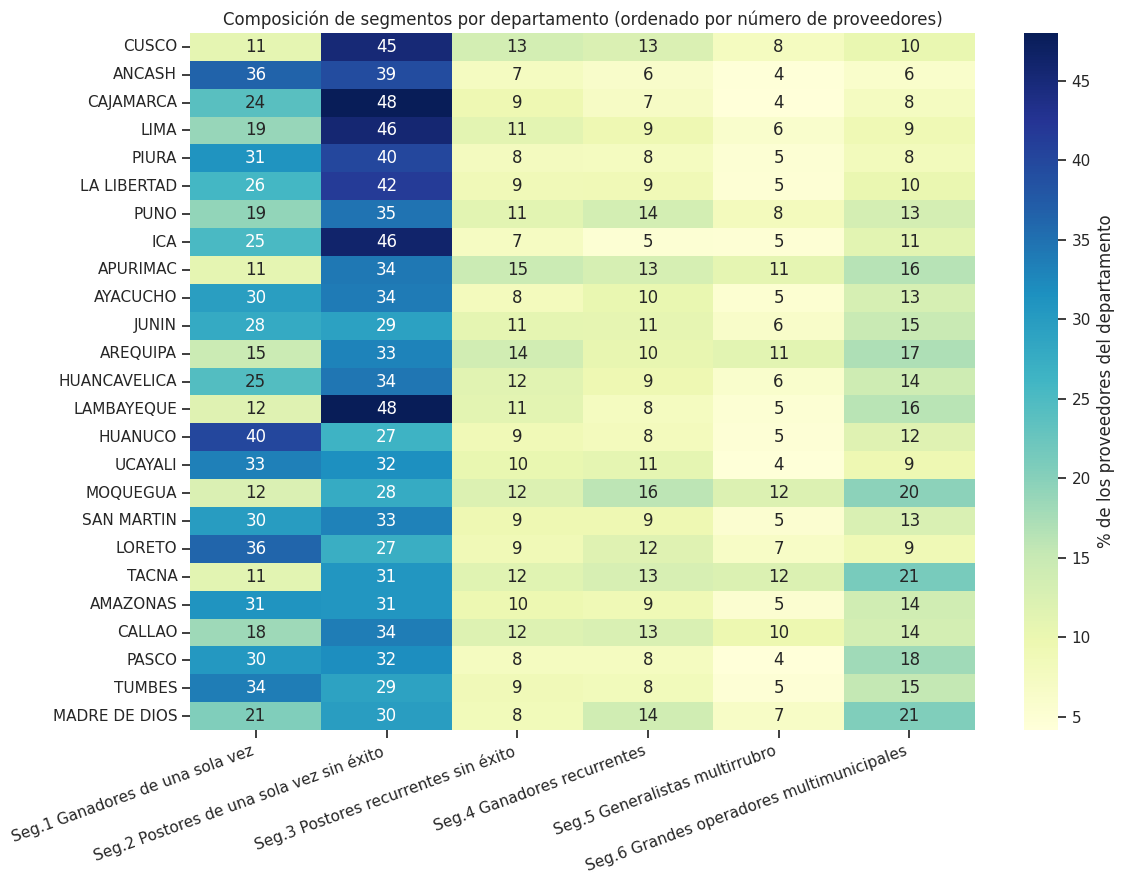

Departamentos con mayor % de proveedores recurrentes (segmentos 2 a 5):


,Recurrentes_pct
departamento,
MOQUEGUA,59.8
TACNA,57.9
APURIMAC,54.8
AREQUIPA,52.4
MADRE DE DIOS,49.6


Departamentos con menor %:


,Recurrentes_pct
departamento,
LA LIBERTAD,32.6
PIURA,28.8
ICA,28.4
CAJAMARCA,28.0
ANCASH,24.2


In [ ]:
# departamento de cada provincia, para el mapa de calor
dptos = d[["ruc_proveedor", "segmento", "departamentos_participacion"]].copy()
dptos["departamento"] = dptos["departamentos_participacion"].str.split(",")
dptos = dptos.explode("departamento").reset_index(drop=True)
dptos["departamento"] = dptos["departamento"].map(normalizar_texto)
dptos = dptos.drop_duplicates(["ruc_proveedor", "departamento"])

por_dpto = pd.crosstab(dptos["departamento"], dptos["segmento"])
por_dpto_pct = por_dpto.div(por_dpto.sum(axis=1), axis=0) * 100
por_dpto_pct = por_dpto_pct.loc[por_dpto.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(por_dpto_pct, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "% de los proveedores del departamento"})
ax.set(title="Composición de segmentos por departamento (ordenado por número de proveedores)", xlabel="", ylabel="")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

recurrentes = por_dpto_pct[[nombres_segmentos[i] for i in (2, 3, 4, 5)]].sum(axis=1).sort_values(ascending=False)
print("Departamentos con mayor % de proveedores recurrentes (segmentos 2 a 5):")
display(recurrentes.head(5).round(1).to_frame("Recurrentes_pct"))
print("Departamentos con menor %:")
display(recurrentes.tail(5).round(1).to_frame("Recurrentes_pct"))



- **Más recurrentes (segmentos 2 a 5):** Moquegua 59,8 %, Tacna 57,9 %, Apurímac 54,8 %, Arequipa 52,4 % y Madre de Dios 49,6 %.
- **Menos recurrentes:** Áncash 24,2 %, Cajamarca 28,0 %, Ica 28,4 %, Piura 28,8 % y La Libertad 32,6 %. En esos departamentos entre el 67 % y el 76 % de los proveedores participa una sola vez.
- El departamento de **Lima** (4 362 proveedores, que incluye a la provincia de Lima y a las provincias de la región) tiene 35,6 % de recurrentes: ocupa el puesto 18 de 25 (incluido el Callao), por debajo de los departamentos del sur y por encima de Áncash, Cajamarca, Ica, Piura y La Libertad.
- Los **grandes operadores** pesan más en Tacna (21 %), Madre de Dios (21 %), Moquegua (20 %) y Pasco (18 %), y menos en Áncash (6 %), Cajamarca (8 %) y Piura (8 %).

**Lectura:** el mercado de proveedores del sur es más "estable" (los mismos proveedores vuelven a participar), mientras que en el norte y la costa central predomina la participación puntual. Es una asociación descriptiva: no se sabe todavía si responde al tipo de obras, a la cantidad de proveedores locales o a barreras de entrada.


# <font color=green>10. Conclusiones preliminares</font>

**Estas conclusiones son preliminares:** describen lo que muestran los datos con la configuración actual y se confirmarán en el Hito 4. Todos los resultados incluyen la provincia de Lima.

## 10.1 Resumen de decisiones y parámetros

| Decisión | Parámetro o criterio | Resultado |
|---|---|---|
| Aplicar `log1p` | Asimetría mayor a 1 | 6 de 7 variables; sin `log1p`, K-means aísla a 1 proveedor (k = 4 a 6) |
| `StandardScaler` y no `RobustScaler` | Rango intercuartil | Es 0 en 3 variables; el escalado robusto daría pesos arbitrarios |
| PCA con 3 componentes | Regla del 85 % frente a Kaiser | 91,4 % de varianza; Z3 es el único que captura `n_rubros` |
| NMF con 4 patrones | Error de reconstrucción menor o igual a 10 % | 9,8 % con k = 4 |
| K-means con k = 6 | Cluster mínimo de 1 %, ARI de 0,90 o más, mayor silueta común | k = 6 en las tres representaciones |
| DBSCAN con `min_samples` = 50 y `eps` = 0,5 | Ruido menor o igual a 5 %, mayor silueta | 4 clusters, 1,8 % de ruido; con `eps` = 0,3 el ruido sería 5,03 % |
| Jerárquico (Ward) sobre muestra de 8 000 | Memoria y comparación | ARI de 0,989 contra K-means |
| Representación final: PCA de 3 componentes | Silueta común, parsimonia | 0,804 frente a 0,807 de las 7 variables y 0,772 de NMF |
| Penalidades y consorcio fuera del modelo | Evitar circularidad | Se usan solo para interpretar |
| Mapas por provincia con 100 proveedores o más | Estabilidad del porcentaje | 177 de 196 provincias |

## 10.2 Conclusiones preliminares

1. **Hay una estructura de 6 segmentos y no es un artefacto del método.** Tres representaciones y dos algoritmos (K-means y Ward) coinciden entre 0,96 y 0,99 de ARI, y la solución se reproduce con otras semillas y submuestras (ARI mayor a 0,999). Se separan por tres ejes: cuánto participan, si ganan y en cuántos rubros operan.
2. **La mayoría de los proveedores participa una sola vez.** El 78 % pertenece a los segmentos de participación puntual: 29,5 % ganó su única convocatoria (ganadores de una sola vez) y 48,3 % no ganó (postores de una sola vez sin éxito). Solo el 22 % es recurrente.
3. **El dinero se concentra en pocos contratos grandes, no en proveedores recurrentes.** Los ganadores de una sola vez reúnen el 67,6 % del monto adjudicado; los grandes operadores, el 13,3 %. El 1 % de los proveedores concentra el 41,9 % del monto.
4. **Los grandes operadores pesan más en el territorio que en el padrón.** Son el 2,76 % de los proveedores pero el 20,6 % de las apariciones por provincia, con 8 municipalidades en mediana. Es el segmento menos definido (11,3 % de sus proveedores es ambiguo): su límite con los ganadores recurrentes es gradual.
5. **El territorio importa.** En Moquegua, Tacna, Apurímac y Arequipa más de la mitad de los proveedores es recurrente; en Áncash, Cajamarca, Ica, Piura y La Libertad lo es menos del 33 %.
6. **Lima es la provincia con más proveedores y tiene un perfil propio.** Con 2 319 proveedores supera a Espinar (1 808), pero solo el 9,8 % son ganadores de una sola vez (mediana provincial de 22,0 %) y el 49,2 % son postores de una sola vez sin éxito. Los grandes operadores pesan 9,8 % frente a 20,1 % de mediana. El 65,8 % de sus proveedores participa solo en Lima.
7. **Más actividad se asocia con más consorcio y más penalidades** (consorcio de 7 % a 53 %; penalidades de 1 % a 14 %), aunque estas variables no entraron al modelo. Es una asociación descriptiva, no un efecto causal.
8. **Sobre las técnicas.** `log1p` es la decisión que más cambia el resultado. PCA no mejora la separación frente a las 7 variables, pero la resume en 3 ejes interpretables. NMF separa algo menos, aunque descompone la actividad en trayectoria y escala. DBSCAN reconoce solo dos grandes zonas (sin y con adjudicación) y deja como ruido a los segmentos raros.

**Qué todavía no se puede afirmar:** que k = 6 sea el número definitivo (los criterios no distinguen entre 6 y 7 por silueta), que los nombres sean los finales, ni que las diferencias territoriales (incluida la de Lima) tengan una causa. Tampoco se puede dar por buena la lectura de penalidades hasta resolver los problemas de datos de la sección siguiente.



# <font color=green>11. Problemas y trabajo pendiente</font>


1. **Perfiles repetidos (53,9 %).** Inflan la silueta y obligaron a ejecutar DBSCAN con perfiles únicos y pesos. La silueta alta de los segmentos 0 y 1 no prueba segmentos naturales: refleja que muchos proveedores son idénticos.
2. **Segmentos con frontera difusa.** El 11,3 % de los grandes operadores y el 3,3 % de los ganadores recurrentes quedaría más cerca de otro segmento. Falta decidir si se mantienen separados o se tratan como una escala de intensidad.
3. **Elección de k.** La silueta de k = 6 y k = 7 casi empata; se eligió 6 por Davies-Bouldin y tamaño mínimo, pero falta contrastarlo con criterio de negocio (5, 6 o 7 segmentos).
4. **DBSCAN depende de un umbral.** La regla de ruido de 5 % elige `eps` = 0,5; con `eps` = 0,3 el ruido es 5,03 % y el resultado sería otro (5 clusters). Falta probar umbrales alternativos o una rejilla más fina antes de usar DBSCAN más allá del contraste.
5. **Lima como caso particular.** Es la provincia con más proveedores y con un perfil distinto (pocos ganadores de una sola vez, muchos postores sin éxito); además, 1 527 proveedores participan solo en Lima. Falta revisar si su comportamiento responde al volumen de procesos o a la naturaleza de sus contrataciones, y si conviene analizarla por separado.
6. **Cobertura territorial.** Con Lima incluida, las 196 provincias tienen datos, pero 19 tienen menos de 100 proveedores (no se muestran en los mapas de porcentaje). Cada proveedor cuenta en todas las provincias donde participó, por lo que los conteos suman más que los 47 281 proveedores.
9. **Alternativa evaluada y descartada fuera de este cuaderno.** Segmentar por separado a los proveedores con y sin adjudicación dio una partición casi igual a la global (ARI entre 0,96 y 0,98) y no mejoró las métricas. Esta prueba se hizo con la matriz anterior (sin Lima) y conviene repetirla.



# <font color=green>12. Guardado de resultados</font>

In [ ]:
d[["ruc_proveedor", "cluster", "segmento"]].to_csv("etiquetas_segmentos.csv", index=False)
resultados_kmeans.to_csv("comparacion_kmeans.csv", index=False)
comparacion.to_csv("comparacion_metodos.csv", index=False)
print("Guardados: etiquetas_segmentos.csv, comparacion_kmeans.csv y comparacion_metodos.csv")

Guardados: etiquetas_segmentos.csv, comparacion_kmeans.csv y comparacion_metodos.csv
